# Лабораторная работа 4

Анализ искусственного многомерного датасета: генерация, описательная статистика, raincloud-графики, парные scatterplot-графики и корреляционные heat-map.

## [1.1] Генерация датасета

Для каждого из трёх классов генерируется по 100 объектов из многомерного нормального распределения. Признаки непрерывные, центры классов фиксированы, ковариационная матрица выбрана диагональной.

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from IPython.display import display

# Готовые визуализации из tsr/plots
import sys
from pathlib import Path
PLOTS_DIR = Path.cwd() / "tsr" / "plots"
if not PLOTS_DIR.exists():
    PLOTS_DIR = Path.cwd() / "plots"
sys.path.insert(0, str(PLOTS_DIR))
from raincloud import raincloud_horizontal
from scatterplot import scatter2d

# Фиксируем генератор для воспроизводимости результата.
rng = np.random.default_rng(42)

FEATURES = [f"X{i}" for i in range(1, 9)]
CLASS_COL = "class"
N_PER_CLASS = 100

centers = {
    0: np.array([+1, +1, +1, +1, +1, +1, +1, +1], dtype=float),
    1: np.array([-1, -1, -1, -1, -1, -1, -1, -1], dtype=float),
    2: np.array([+1, -1, +1, -1, +1, -1, +1, -1], dtype=float),
}

# Небольшая дисперсия сохраняет различимость классов,
# но оставляет признаки недискретными (вещественными).
covariance = 0.20 * np.eye(len(FEATURES))

parts = []
for class_id, center in centers.items():
    observations = rng.multivariate_normal(
        mean=center, cov=covariance, size=N_PER_CLASS
    )
    part = pd.DataFrame(observations, columns=FEATURES)
    part[CLASS_COL] = class_id
    parts.append(part)

df = pd.concat(parts, ignore_index=True)
df = df[FEATURES + [CLASS_COL]]

print(f"Размер df: {df.shape}")
display(df.head())
display(df.groupby(CLASS_COL).size().rename('n').to_frame())

Размер df: (300, 9)


,X1,X2,X3,X4,X5,X6,X7,X8,class
0,1.136274,0.534905,1.335612,1.420633,0.127471,0.417648,1.057172,0.858572,0
1,0.992486,0.618507,1.393279,1.347839,1.029530,1.504118,1.209077,0.615713,0
2,1.164910,0.571175,1.392855,0.977672,0.917327,0.695479,1.546737,0.930892,0
3,0.808446,0.842521,1.238056,1.163432,1.184580,1.192669,1.957774,0.818246,0
4,0.770918,0.636070,1.275474,1.504892,0.949041,0.624271,0.631281,1.290954,0


,n
class,
0,100
1,100
2,100


## [1.2] Статистика по датасету

Ниже выводятся размерность, типы столбцов, размеры классов, основные описательные оценки, а также количество объектов с NaN и нулевыми значениями по классам.

In [65]:
# Общая информация о размере и типах признаков
summary = pd.DataFrame({
    "Показатель": [
        "Число объектов", "Число количественных признаков",
        "Число классов", "Размерность df (объекты × столбцы)"
    ],
    "Значение": [
        len(df), len(FEATURES), df[CLASS_COL].nunique(), str(df.shape)
    ]
})
print("Общая информация")
display(summary)

print("Типы признаков и целевого столбца")
display(pd.DataFrame({"Тип": df.dtypes.astype(str)}))

print("Количество объектов в каждом классе")
display(df[CLASS_COL].value_counts().sort_index().rename("Количество объектов").to_frame())

print("Описательные оценки количественных признаков")
display(df[FEATURES].describe().T.round(4))

# Для каждого класса считаем число строк, где есть хотя бы один NaN
nan_by_class = df.groupby(CLASS_COL)[FEATURES].apply(
    lambda block: block.isna().any(axis=1).sum()
).rename("Объектов хотя бы с одним NaN").to_frame()
print("Объекты с NaN по классам")
display(nan_by_class)

# Для каждого класса считаем число строк, где есть хотя бы один нулевой признак
zero_by_class = df.groupby(CLASS_COL)[FEATURES].apply(
    lambda block: block.eq(0).any(axis=1).sum()
).rename("Объектов хотя бы с одним нулём").to_frame()
print("Объекты с нулевыми значениями по классам")
display(zero_by_class)

# Дополнительно показываем число NaN и нулей по каждому признаку внутри каждого класса
missing_zero_detail = []
for class_id, block in df.groupby(CLASS_COL):
    for feature in FEATURES:
        missing_zero_detail.append({
            CLASS_COL: class_id, "Признак": feature,
            "NaN": int(block[feature].isna().sum()),
            "Нулей": int(block[feature].eq(0).sum())
        })
print("Детализация NaN и нулей по признакам")
display(pd.DataFrame(missing_zero_detail).pivot(index="Признак", columns=CLASS_COL, values=["NaN", "Нулей"]))

Общая информация


,Показатель,Значение
0,Число объектов,300
1,Число количественных признаков,8
2,Число классов,3
3,Размерность df (объекты × столбцы),"(300, 9)"


Типы признаков и целевого столбца


,Тип
X1,float64
X2,float64
X3,float64
X4,float64
X5,float64
X6,float64
X7,float64
X8,float64
class,int64


Количество объектов в каждом классе


,Количество объектов
class,
0,100
1,100
2,100


... (4 outputs left out)

Объекты с нулевыми значениями по классам


,Объектов хотя бы с одним нулём
class,
0,0
1,0
2,0


Детализация NaN и нулей по признакам


NaN       Нулей      
class     0  1  2     0  1  2
Признак                      
X1        0  0  0     0  0  0
X2        0  0  0     0  0  0
X3        0  0  0     0  0  0
X4        0  0  0     0  0  0
X5        0  0  0     0  0  0
X6        0  0  0     0  0  0
X7        0  0  0     0  0  0
X8        0  0  0     0  0  0

## [1.3] 1D-визуализация: raincloud plot с jittering

Функция ниже строит для каждого признака violin-часть raincloud-графика, jittered-точки и boxplot. В boxplot отображаются медиана, IQR и whiskers Range (от минимума до максимума). Параметры оценок можно изменить в словаре `RAIN_CONFIG`.

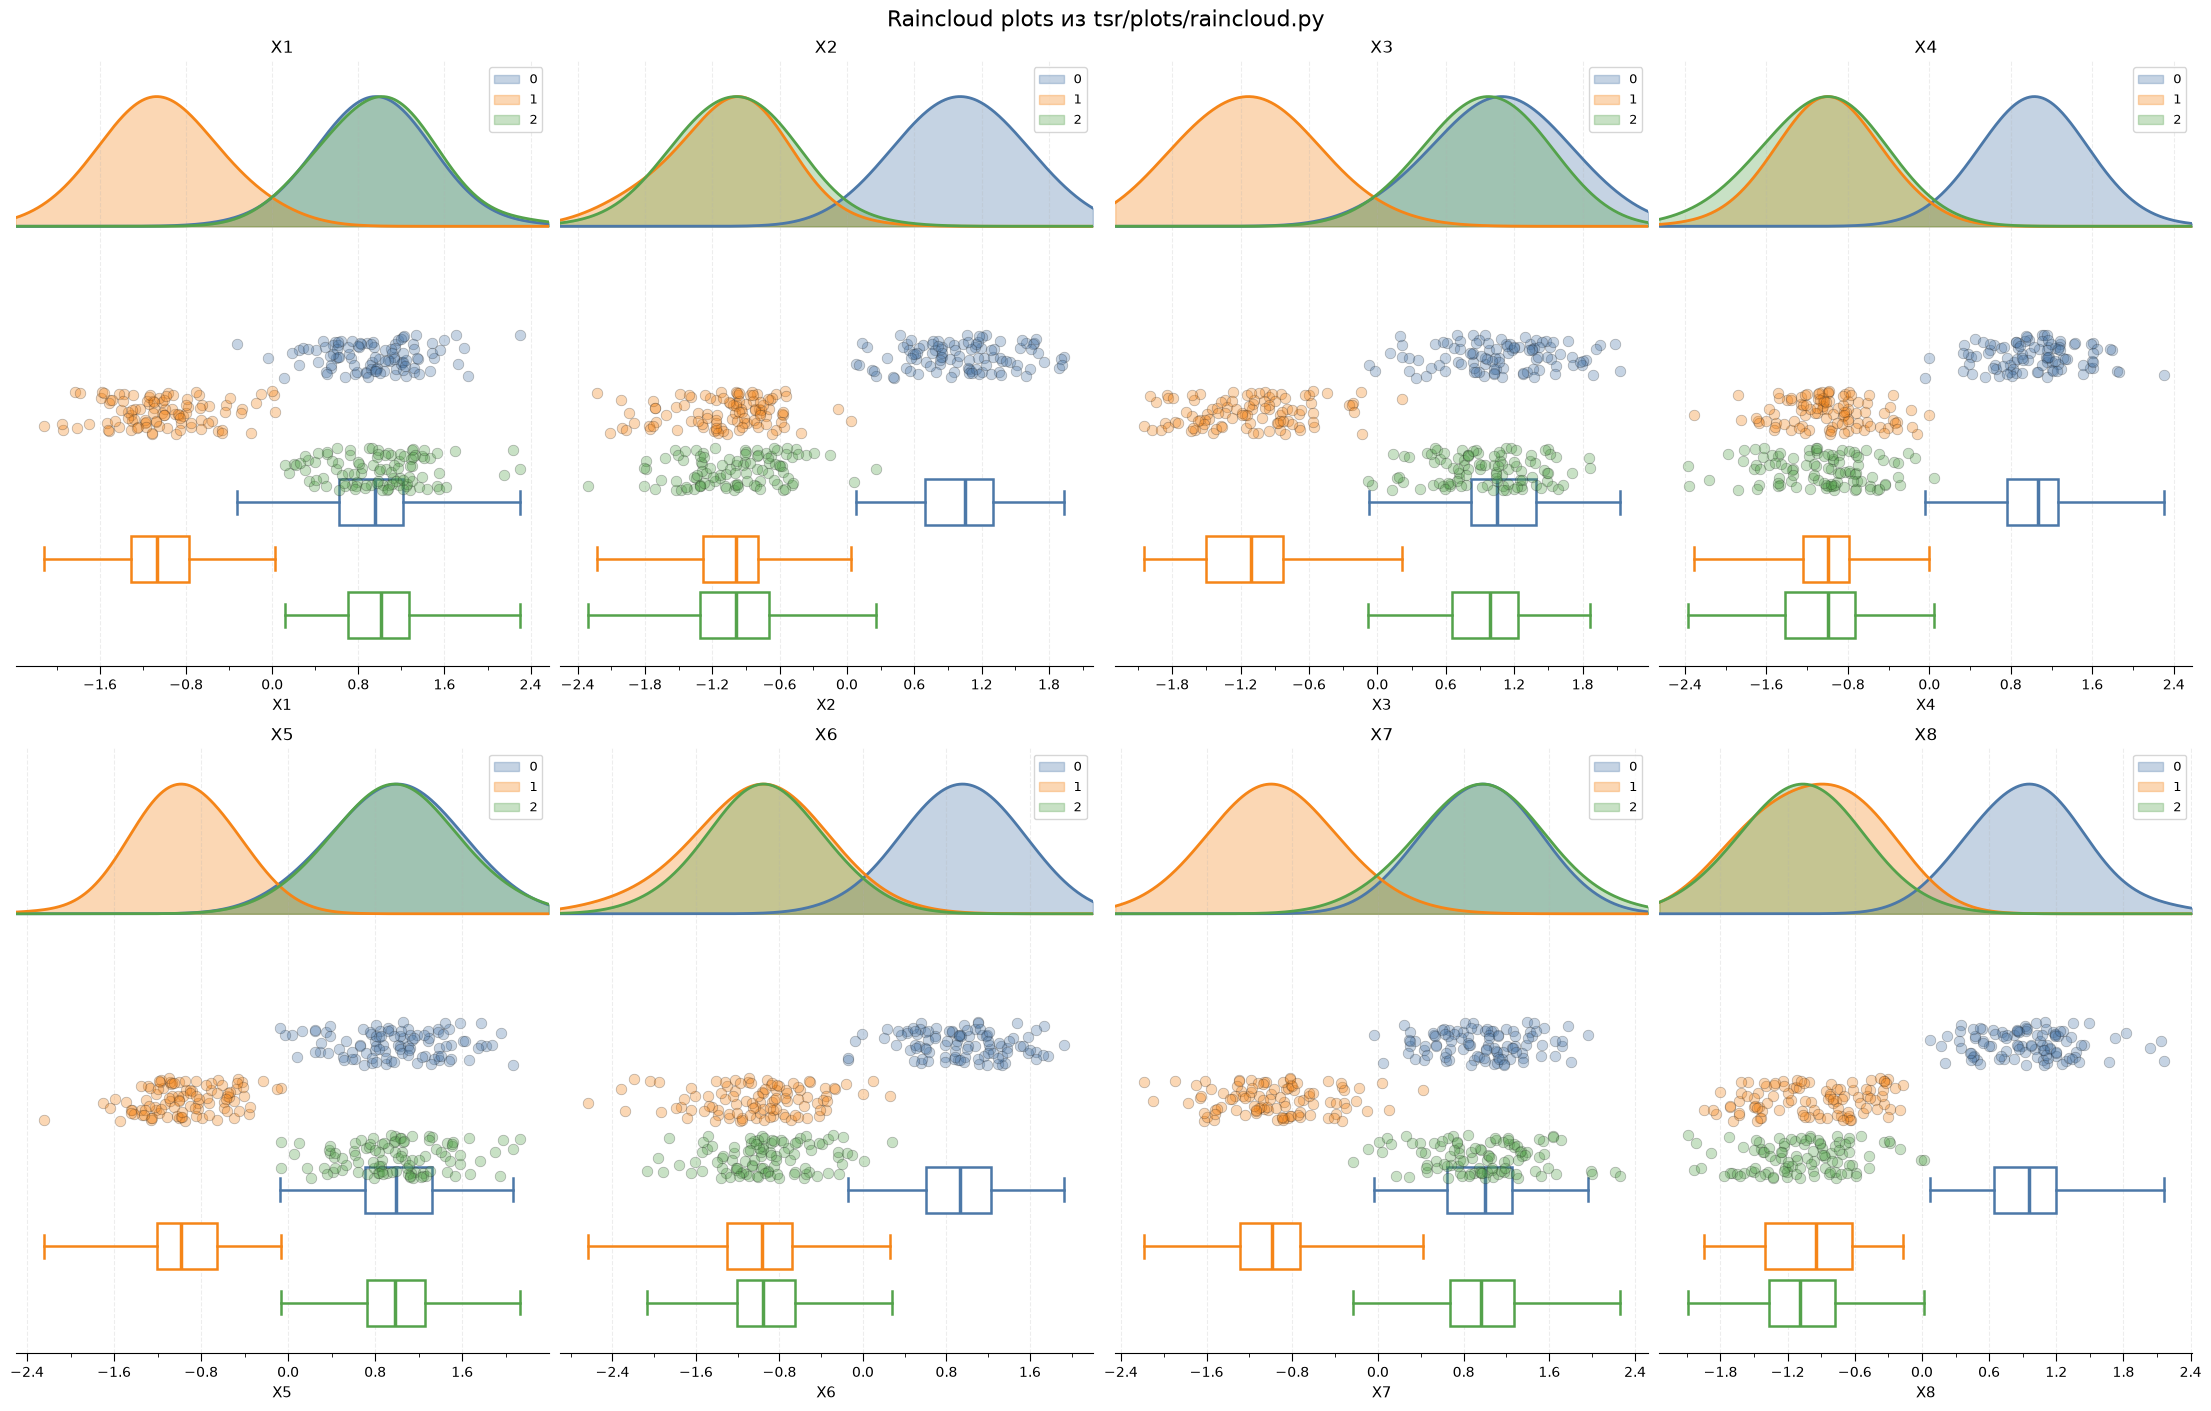

In [66]:
CLASS_PALETTE = {0: "#4C78A8", 1: "#F58518", 2: "#54A24B"}

# Используем готовую реализацию raincloud_horizontal из tsr/plots/raincloud.py.
# Можно менять boxplot_whiskers на (0, 100) для Range или на (25, 75) для IQR.
RAIN_CONFIG = {
    "figsize": (22, 14),
    "boxplot_whiskers": (0, 100),
    "kde_bandwidth": 0.85,
    "kde_alpha": 0.32,
    "point_alpha": 0.32,
    "show_legend": True,
}

fig, axes = plt.subplots(
    nrows=2, ncols=4, figsize=RAIN_CONFIG["figsize"],
    constrained_layout=True
)
for ax, feature in zip(axes.ravel(), FEATURES):
    raincloud_horizontal(
        dataset=df,
        feature_name=feature,
        class_column=CLASS_COL,
        class_order=sorted(df[CLASS_COL].unique()),
        class_colors=CLASS_PALETTE,
        axis=ax,
        boxplot_whiskers=RAIN_CONFIG["boxplot_whiskers"],
        kde_bandwidth=RAIN_CONFIG["kde_bandwidth"],
        kde_alpha=RAIN_CONFIG["kde_alpha"],
        show_legend=RAIN_CONFIG["show_legend"],
        x_label=feature,
        random_state=42,
        point_alpha=RAIN_CONFIG["point_alpha"],
    )
    ax.set_title(feature, fontsize=RAIN_CONFIG.get("title_size", 12))
fig.suptitle("Raincloud plots из tsr/plots/raincloud.py", fontsize=16)
plt.show()

## [1.4] 2D-визуализация всех пар признаков

`PAIR_CONFIG` содержит параметры цветов, толщины осей, шага больших и малых рисок, сетки, квадратности, шрифтов, легенды, заголовков и прозрачности. Для каждой пары строятся scatterplot и маргинальные KDE-плотности классов по обеим осям.

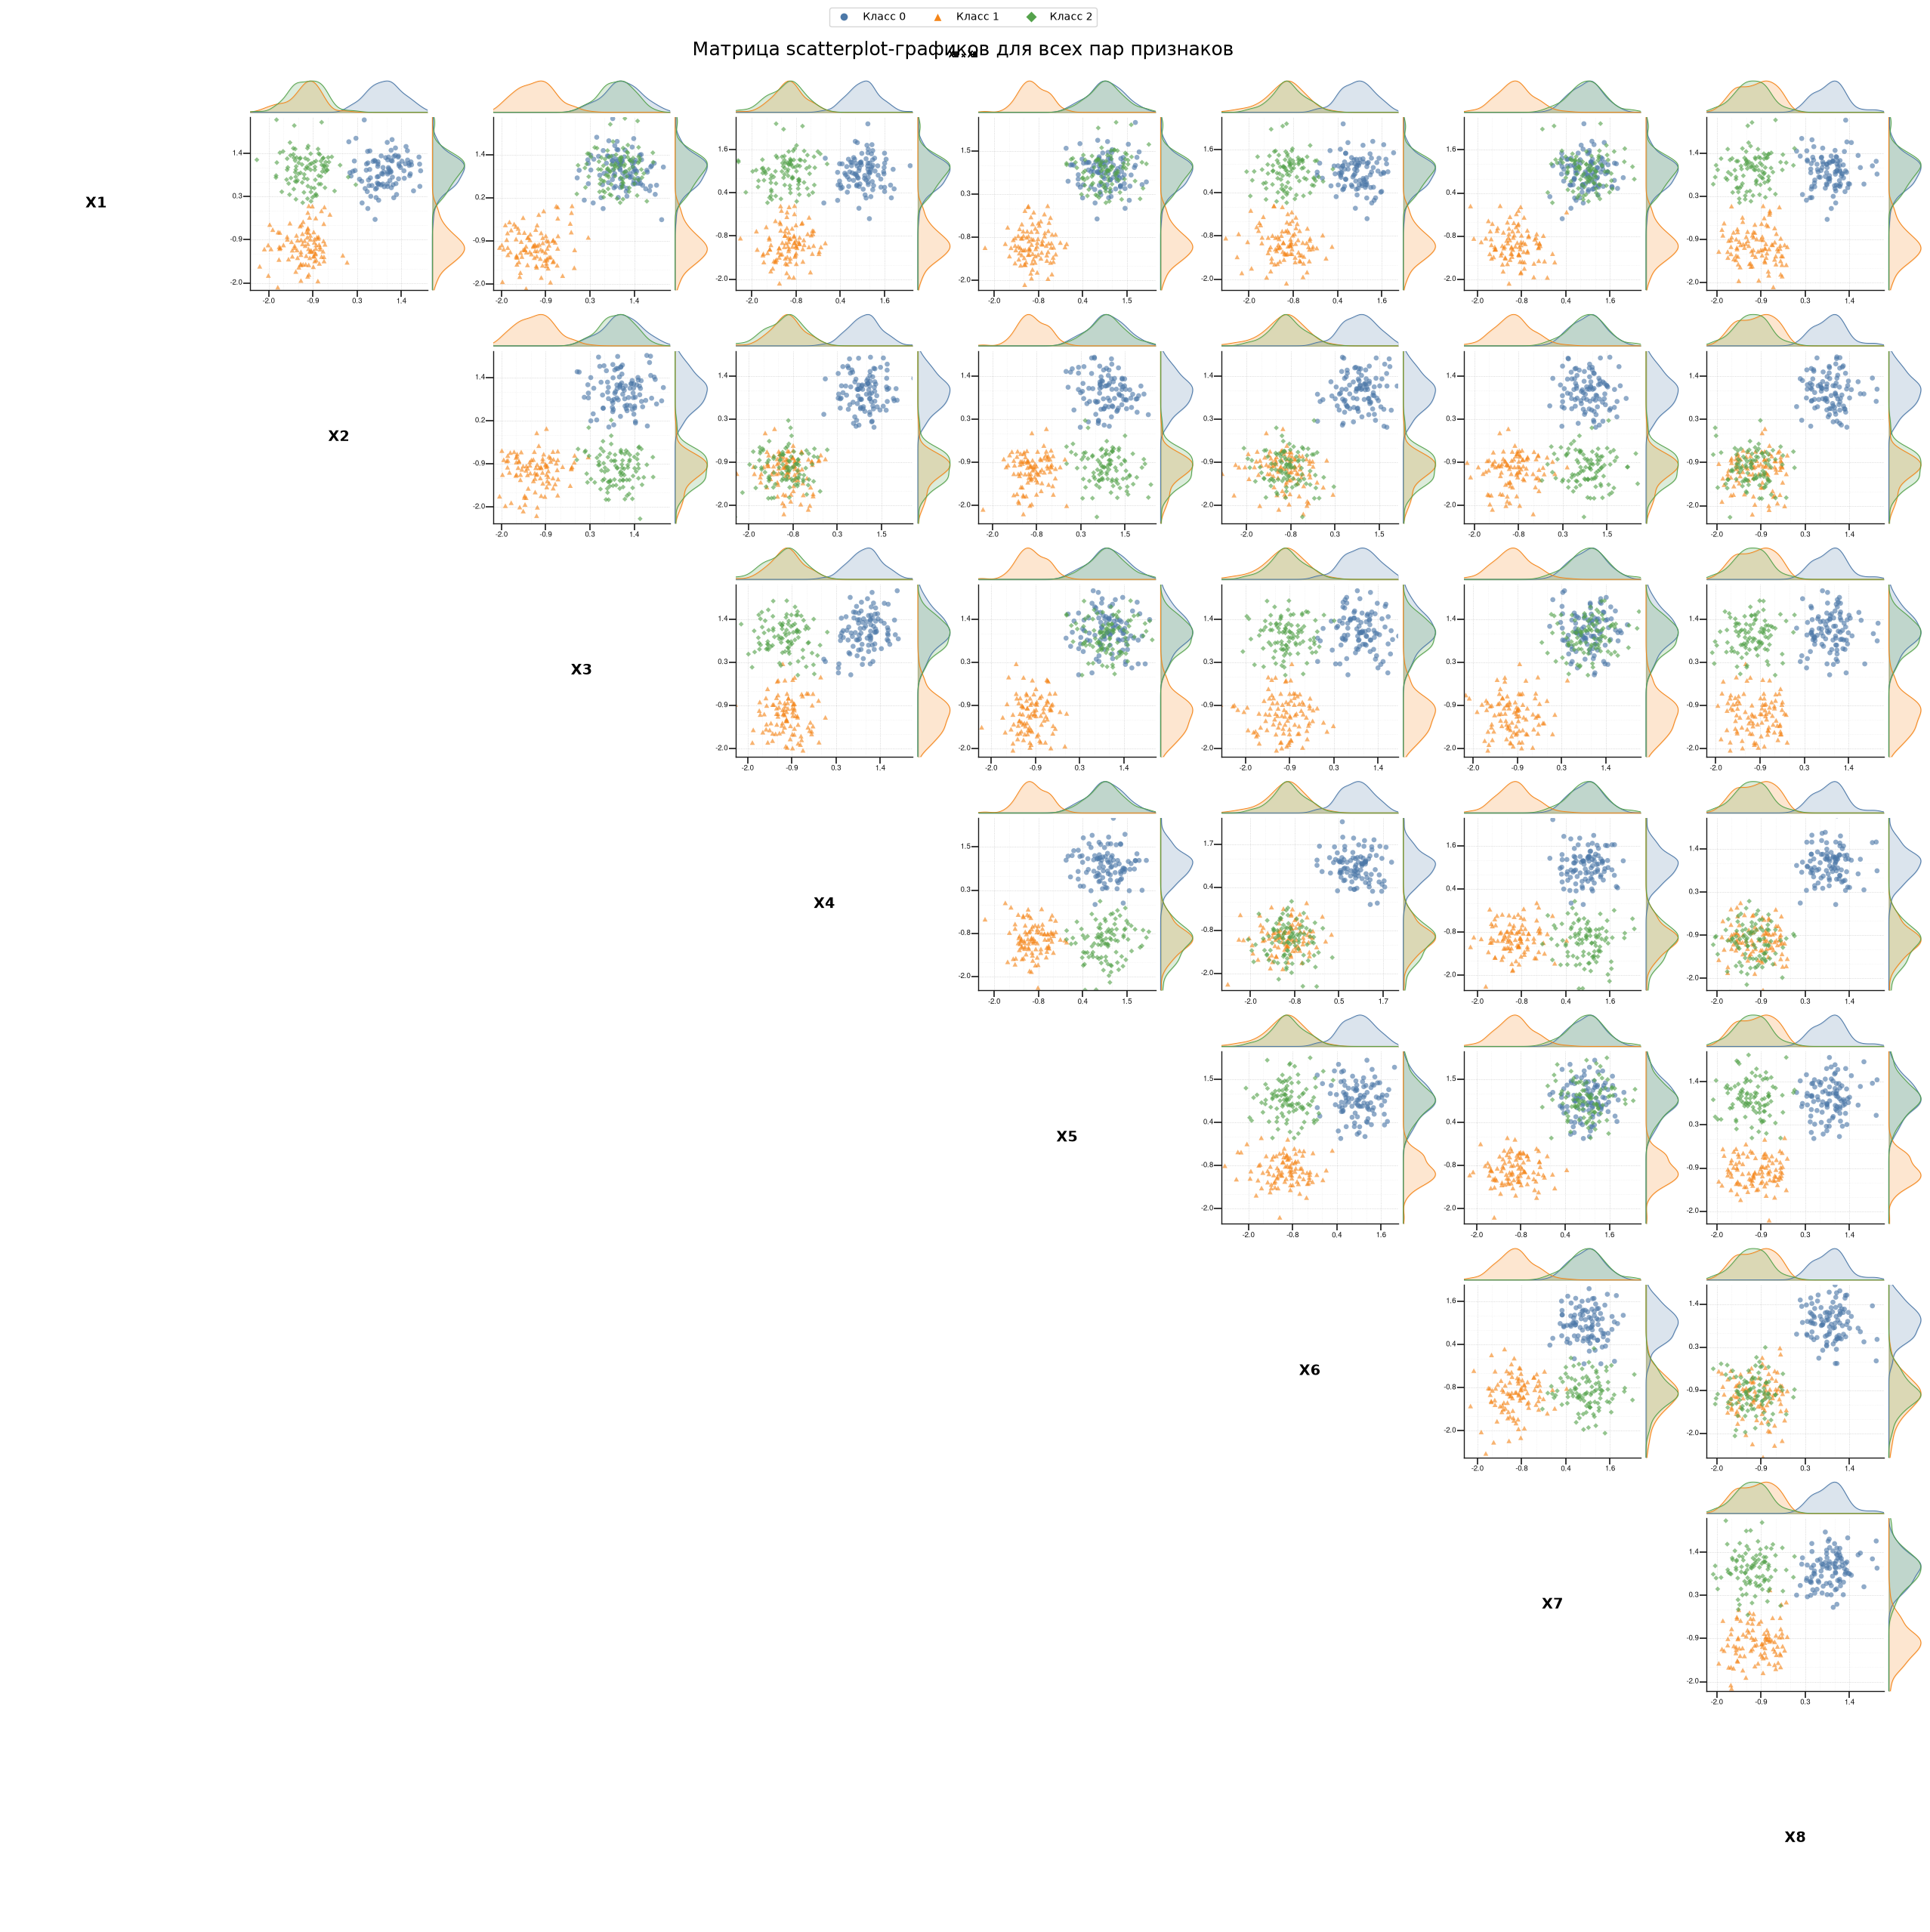

In [67]:
# scatter2d — готовый низкоуровневый scatterplot из tsr/plots/scatterplot.py.
# Все параметры ниже можно менять пользователю.
PAIR_CONFIG = {
    "fig_size": 4.0,
    "axis_linewidth": 1.0,
    "n_major_ticks": 5,
    "tick_start": -2.0,
    "n_minor_ticks": 2,
    "show_ticks": True,
    "show_grid": True,
    "grid_alpha": 0.28,
    "grid_linewidth": 0.6,
    "grid_linestyle": ":",
    "point_alpha": 0.62,
    "density_alpha": 0.20,
    "legend": True,
    "title_size": 8,
    "font_size": 7,
}

SCATTER_CONFIG = {
    "figure": {"size": PAIR_CONFIG["fig_size"], "dpi": 120,
                "legend": False, "title_size": PAIR_CONFIG["title_size"]},
    "font": {"tick_size": PAIR_CONFIG["font_size"],
             "label_size": PAIR_CONFIG["font_size"], "legend_size": 9},
    "axes": {"linewidth": PAIR_CONFIG["axis_linewidth"],
             "square_data_area": True},
    "ticks": {"major_count": PAIR_CONFIG["n_major_ticks"],
              "major_start": PAIR_CONFIG["tick_start"],
              "minor_count": PAIR_CONFIG["n_minor_ticks"]},
    "grid": {"show": PAIR_CONFIG["show_grid"],
             "alpha": PAIR_CONFIG["grid_alpha"],
             "linewidth": PAIR_CONFIG["grid_linewidth"],
             "linestyle": PAIR_CONFIG["grid_linestyle"]},
    "points": {"alpha": PAIR_CONFIG["point_alpha"], "size": 18},
    "classes": {
        0: {"color": CLASS_PALETTE[0], "shape": "circle"},
        1: {"color": CLASS_PALETTE[1], "shape": "triangle_up"},
        2: {"color": CLASS_PALETTE[2], "shape": "diamond"},
    },
    "regression": {"show": False},
    "class_regression": {"show": False},
    "density": {"show": False},
}

from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D

def add_class_marginal_densities(result, data, feature_x, feature_y, alpha=0.20):
    """Добавляет цветные KDE классов по X и Y в ячейку матрицы."""
    ax = result.ax
    top = ax.inset_axes([0, 1.02, 1, 0.20], sharex=ax)
    right = ax.inset_axes([1.02, 0, 0.20, 1], sharey=ax)
    for class_id in sorted(data[CLASS_COL].unique()):
        block = data[data[CLASS_COL] == class_id]
        color = CLASS_PALETTE[class_id]
        x_values = block[feature_x].to_numpy()
        y_values = block[feature_y].to_numpy()
        if len(x_values) > 1 and np.std(x_values) > 0:
            x_grid = np.linspace(*ax.get_xlim(), 120)
            x_density = gaussian_kde(x_values)(x_grid)
            x_density /= max(x_density.max(), 1e-12)
            top.fill_between(x_grid, 0, x_density, color=color, alpha=alpha)
            top.plot(x_grid, x_density, color=color, linewidth=0.7)
        if len(y_values) > 1 and np.std(y_values) > 0:
            y_grid = np.linspace(*ax.get_ylim(), 120)
            y_density = gaussian_kde(y_values)(y_grid)
            y_density /= max(y_density.max(), 1e-12)
            right.fill_betweenx(y_grid, 0, y_density, color=color, alpha=alpha)
            right.plot(y_density, y_grid, color=color, linewidth=0.7)
    top.tick_params(axis="both", labelbottom=False, labelleft=False, length=0)
    right.tick_params(axis="both", labelbottom=False, labelleft=False, length=0)
    for marginal in (top, right):
        marginal.grid(False)
        marginal.set_facecolor("none")
        for spine in marginal.spines.values():
            spine.set_visible(False)

# Одна фигура-матрица 8×8. На диагонали сохранены подписи признаков,
# в верхнем треугольнике — все уникальные пары признаков.
n_features = len(FEATURES)
fig, axes = plt.subplots(
    n_features, n_features,
    figsize=(n_features * 3.2, n_features * 3.2),
    squeeze=False
)

for row, feature_y in enumerate(FEATURES):
    for col, feature_x in enumerate(FEATURES):
        ax = axes[row, col]
        if row == col:
            ax.axis("off")
            ax.text(0.5, 0.5, feature_x, ha="center", va="center",
                    fontsize=14, fontweight="bold")
        elif col > row:
            result = scatter2d(
                df, x=feature_x, y=feature_y, class_column=CLASS_COL,
                class_order=sorted(df[CLASS_COL].unique()), config=SCATTER_CONFIG,
                title=f"{feature_x} × {feature_y}", ax=ax,
                show_ticks=PAIR_CONFIG["show_ticks"],
                show_grid=PAIR_CONFIG["show_grid"],
                n_major_ticks=PAIR_CONFIG["n_major_ticks"],
                tick_start=PAIR_CONFIG["tick_start"],
                n_minor_ticks=PAIR_CONFIG["n_minor_ticks"],
                axis_linewidth=PAIR_CONFIG["axis_linewidth"],
                grid_alpha=PAIR_CONFIG["grid_alpha"],
                grid_linestyle=PAIR_CONFIG["grid_linestyle"],
                grid_linewidth=PAIR_CONFIG["grid_linewidth"],
                point_alpha=PAIR_CONFIG["point_alpha"],
                density=False, regression=False, class_regression=False,
            )
            add_class_marginal_densities(
                result, df, feature_x, feature_y, PAIR_CONFIG["density_alpha"]
            )
        else:
            # Второй треугольник оставляем пустым, чтобы не дублировать пары.
            ax.axis("off")

if PAIR_CONFIG["legend"]:
    legend_handles = [
        Line2D([0], [0], marker="o", color="w", label="Класс 0",
               markerfacecolor=CLASS_PALETTE[0], markersize=8),
        Line2D([0], [0], marker="^", color="w", label="Класс 1",
               markerfacecolor=CLASS_PALETTE[1], markersize=8),
        Line2D([0], [0], marker="D", color="w", label="Класс 2",
               markerfacecolor=CLASS_PALETTE[2], markersize=8),
    ]
    fig.legend(handles=legend_handles, loc="upper center", ncol=3,
               bbox_to_anchor=(0.5, 1.0))
fig.suptitle("Матрица scatterplot-графиков для всех пар признаков", fontsize=18)
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

## [1.5] Корреляции Пирсона и Спирмена

Heat-map-таблицы строятся для всего датасета и отдельно для каждого класса.

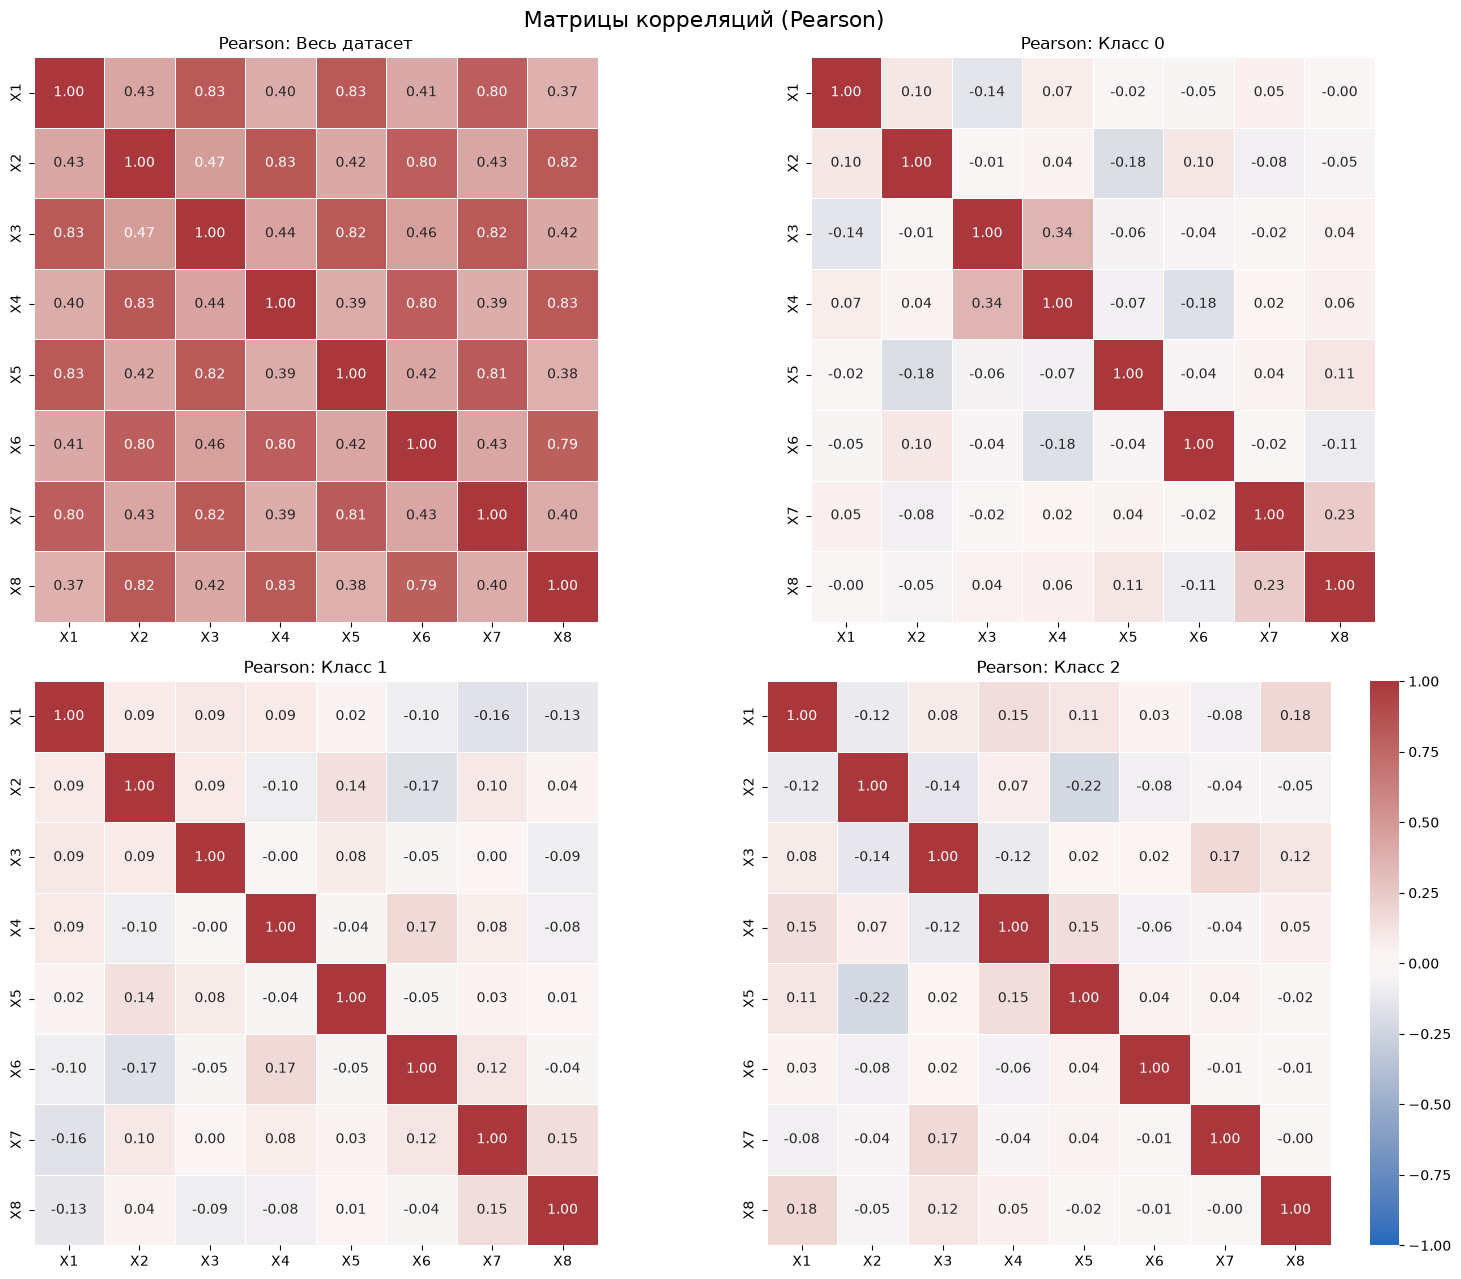

Табличные значения: Pearson
Весь датасет


,X1,X2,X3,X4,X5,X6,X7,X8
X1,1.000,0.428,0.826,0.396,0.826,0.407,0.799,0.367
X2,0.428,1.000,0.471,0.831,0.416,0.798,0.429,0.821
X3,0.826,0.471,1.000,0.442,0.822,0.459,0.821,0.420
X4,0.396,0.831,0.442,1.000,0.393,0.803,0.388,0.827
X5,0.826,0.416,0.822,0.393,1.000,0.423,0.814,0.383
X6,0.407,0.798,0.459,0.803,0.423,1.000,0.428,0.790
X7,0.799,0.429,0.821,0.388,0.814,0.428,1.000,0.396
X8,0.367,0.821,0.420,0.827,0.383,0.790,0.396,1.000


Класс 0


,X1,X2,X3,X4,X5,X6,X7,X8
X1,1.000,0.102,-0.143,0.072,-0.019,-0.047,0.054,-0.004
X2,0.102,1.000,-0.011,0.036,-0.183,0.102,-0.084,-0.047
X3,-0.143,-0.011,1.000,0.344,-0.058,-0.036,-0.023,0.040
X4,0.072,0.036,0.344,1.000,-0.075,-0.179,0.020,0.060
X5,-0.019,-0.183,-0.058,-0.075,1.000,-0.038,0.045,0.111
X6,-0.047,0.102,-0.036,-0.179,-0.038,1.000,-0.019,-0.105
X7,0.054,-0.084,-0.023,0.020,0.045,-0.019,1.000,0.234
X8,-0.004,-0.047,0.040,0.060,0.111,-0.105,0.234,1.000


Класс 1


,X1,X2,X3,X4,X5,X6,X7,X8
X1,1.000,0.092,0.094,0.091,0.025,-0.101,-0.156,-0.128
X2,0.092,1.000,0.091,-0.100,0.137,-0.172,0.099,0.037
X3,0.094,0.091,1.000,-0.002,0.079,-0.046,0.001,-0.087
X4,0.091,-0.100,-0.002,1.000,-0.042,0.170,0.075,-0.083
X5,0.025,0.137,0.079,-0.042,1.000,-0.046,0.032,0.009
X6,-0.101,-0.172,-0.046,0.170,-0.046,1.000,0.117,-0.042
X7,-0.156,0.099,0.001,0.075,0.032,0.117,1.000,0.149
X8,-0.128,0.037,-0.087,-0.083,0.009,-0.042,0.149,1.000


Класс 2


,X1,X2,X3,X4,X5,X6,X7,X8
X1,1.000,-0.116,0.081,0.154,0.112,0.032,-0.079,0.181
X2,-0.116,1.000,-0.138,0.066,-0.219,-0.085,-0.039,-0.047
X3,0.081,-0.138,1.000,-0.117,0.022,0.018,0.170,0.117
X4,0.154,0.066,-0.117,1.000,0.153,-0.063,-0.036,0.054
X5,0.112,-0.219,0.022,0.153,1.000,0.040,0.041,-0.023
X6,0.032,-0.085,0.018,-0.063,0.040,1.000,-0.013,-0.008
X7,-0.079,-0.039,0.170,-0.036,0.041,-0.013,1.000,-0.002
X8,0.181,-0.047,0.117,0.054,-0.023,-0.008,-0.002,1.000


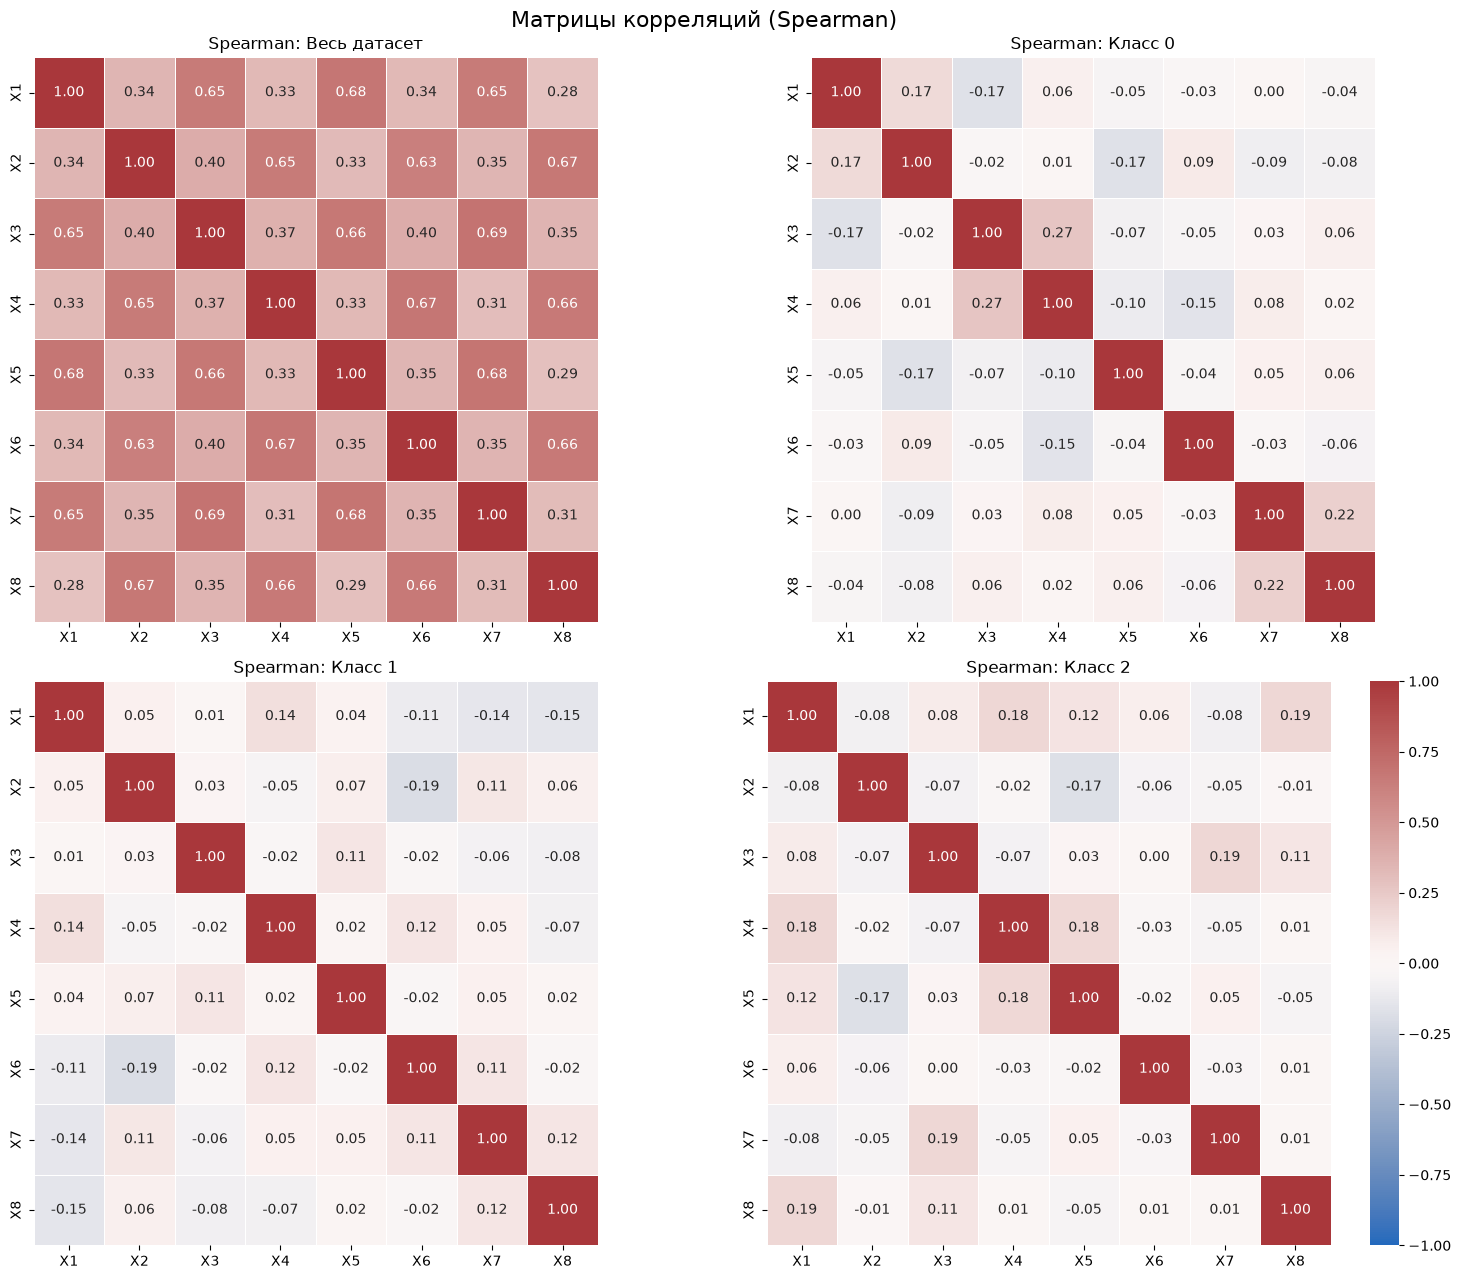

Табличные значения: Spearman
Весь датасет


,X1,X2,X3,X4,X5,X6,X7,X8
X1,1.000,0.345,0.653,0.334,0.677,0.336,0.648,0.282
X2,0.345,1.000,0.397,0.653,0.326,0.631,0.351,0.669
X3,0.653,0.397,1.000,0.375,0.665,0.398,0.691,0.355
X4,0.334,0.653,0.375,1.000,0.335,0.673,0.312,0.659
X5,0.677,0.326,0.665,0.335,1.000,0.348,0.680,0.291
X6,0.336,0.631,0.398,0.673,0.348,1.000,0.355,0.661
X7,0.648,0.351,0.691,0.312,0.680,0.355,1.000,0.314
X8,0.282,0.669,0.355,0.659,0.291,0.661,0.314,1.000


Класс 0


,X1,X2,X3,X4,X5,X6,X7,X8
X1,1.000,0.167,-0.169,0.057,-0.052,-0.028,0.003,-0.041
X2,0.167,1.000,-0.020,0.014,-0.165,0.090,-0.092,-0.078
X3,-0.169,-0.020,1.000,0.266,-0.072,-0.051,0.030,0.057
X4,0.057,0.014,0.266,1.000,-0.103,-0.150,0.076,0.018
X5,-0.052,-0.165,-0.072,-0.103,1.000,-0.045,0.054,0.059
X6,-0.028,0.090,-0.051,-0.150,-0.045,1.000,-0.030,-0.056
X7,0.003,-0.092,0.030,0.076,0.054,-0.030,1.000,0.215
X8,-0.041,-0.078,0.057,0.018,0.059,-0.056,0.215,1.000


Класс 1


,X1,X2,X3,X4,X5,X6,X7,X8
X1,1.000,0.049,0.010,0.143,0.040,-0.109,-0.138,-0.148
X2,0.049,1.000,0.028,-0.047,0.067,-0.191,0.107,0.058
X3,0.010,0.028,1.000,-0.017,0.115,-0.022,-0.064,-0.082
X4,0.143,-0.047,-0.017,1.000,0.018,0.116,0.048,-0.074
X5,0.040,0.067,0.115,0.018,1.000,-0.024,0.053,0.021
X6,-0.109,-0.191,-0.022,0.116,-0.024,1.000,0.115,-0.018
X7,-0.138,0.107,-0.064,0.048,0.053,0.115,1.000,0.116
X8,-0.148,0.058,-0.082,-0.074,0.021,-0.018,0.116,1.000


Класс 2


,X1,X2,X3,X4,X5,X6,X7,X8
X1,1.000,-0.076,0.080,0.181,0.124,0.063,-0.078,0.185
X2,-0.076,1.000,-0.067,-0.023,-0.174,-0.056,-0.054,-0.012
X3,0.080,-0.067,1.000,-0.069,0.030,0.003,0.186,0.110
X4,0.181,-0.023,-0.069,1.000,0.179,-0.028,-0.054,0.013
X5,0.124,-0.174,0.030,0.179,1.000,-0.021,0.050,-0.050
X6,0.063,-0.056,0.003,-0.028,-0.021,1.000,-0.035,0.014
X7,-0.078,-0.054,0.186,-0.054,0.050,-0.035,1.000,0.013
X8,0.185,-0.012,0.110,0.013,-0.050,0.014,0.013,1.000


In [68]:
def correlation_heatmaps(data, features):
    groups = [("Весь датасет", data)] + [
        (f"Класс {class_id}", data[data[CLASS_COL] == class_id])
        for class_id in sorted(data[CLASS_COL].unique())
    ]

    for method in ("pearson", "spearman"):
        fig, axes = plt.subplots(2, 2, figsize=(16, 13))
        axes = axes.ravel()
        for ax, (label, block) in zip(axes, groups):
            corr = block[features].corr(method=method)
            sns.heatmap(corr, ax=ax, cmap="vlag", vmin=-1, vmax=1, center=0,
                        annot=True, fmt=".2f", square=True, linewidths=0.4,
                        cbar=ax is axes[-1])
            ax.set_title(f"{method.capitalize()}: {label}")
            ax.set_xlabel("")
            ax.set_ylabel("")
        fig.suptitle(f"Матрицы корреляций ({method.capitalize()})", fontsize=16)
        fig.tight_layout()
        plt.show()

        print(f"Табличные значения: {method.capitalize()}")
        for label, block in groups:
            print(label)
            display(block[features].corr(method=method).round(3))

correlation_heatmaps(df, FEATURES)

## [4.2] Дополнительные датасеты `df_A_B`

На основе `df` создаются отдельные датасеты для всех сочетаний `A ∈ {1, 10, 100, 1000}` и `B ∈ {1, 10, 100}`. В каждый датасет к классу 0 добавляются `A` одинаковых точек с координатами `(-B, +B, -B, +B, -B, +B, -B, +B)`. Количество объектов классов 1 и 2 не изменяется.

In [69]:
A_VALUES = [1, 10, 100, 1000]
B_VALUES = [1, 10, 100]

# Словарь удобен для перебора всех вариантов, а globals() дополнительно
# создаёт переменные с именами df_A_B: например, df_10_100.
datasets_A_B = {}
base_class0_count = int((df[CLASS_COL] == 0).sum())
base_class1_count = int((df[CLASS_COL] == 1).sum())
base_class2_count = int((df[CLASS_COL] == 2).sum())

for A in A_VALUES:
    for B in B_VALUES:
        added_point = np.array([-B, +B, -B, +B, -B, +B, -B, +B], dtype=float)
        added = pd.DataFrame(
            np.tile(added_point, (A, 1)),
            columns=FEATURES
        )
        added[CLASS_COL] = 0

        dataset_name = f"df_{A}_{B}"
        dataset = pd.concat([df, added], ignore_index=True)
        datasets_A_B[(A, B)] = dataset
        globals()[dataset_name] = dataset

# Таблица контроля: размер и количество объектов по классам.
control_rows = []
for (A, B), dataset in datasets_A_B.items():
    counts = dataset[CLASS_COL].value_counts().reindex([0, 1, 2], fill_value=0)
    control_rows.append({
        "Датасет": f"df_{A}_{B}",
        "A": A,
        "B": B,
        "Размер": len(dataset),
        "Класс 0": int(counts[0]),
        "Класс 1": int(counts[1]),
        "Класс 2": int(counts[2]),
        "Координаты добавленных точек": str(tuple([-B, B, -B, B, -B, B, -B, B])),
    })

control_table = pd.DataFrame(control_rows).sort_values(["A", "B"]).reset_index(drop=True)
display(control_table)

assert all(
    dataset[CLASS_COL].value_counts().get(1, 0) == base_class1_count
    and dataset[CLASS_COL].value_counts().get(2, 0) == base_class2_count
    and dataset[CLASS_COL].value_counts().get(0, 0) == base_class0_count + A
    for (A, B), dataset in datasets_A_B.items()
)
print(f"Создано датасетов: {len(datasets_A_B)}")
print("Проверка количества объектов в классах пройдена.")

,Датасет,A,B,Размер,Класс 0,Класс 1,Класс 2,Координаты добавленных точек
0,df_1_1,1,1,301,101,100,100,"(-1, 1, -1, 1, -1, 1, -1, 1)"
1,df_1_10,1,10,301,101,100,100,"(-10, 10, -10, 10, -10, 10, -10, 10)"
2,df_1_100,1,100,301,101,100,100,"(-100, 100, -100, 100, -100, 100, -100, 100)"
3,df_10_1,10,1,310,110,100,100,"(-1, 1, -1, 1, -1, 1, -1, 1)"
4,df_10_10,10,10,310,110,100,100,"(-10, 10, -10, 10, -10, 10, -10, 10)"
5,df_10_100,10,100,310,110,100,100,"(-100, 100, -100, 100, -100, 100, -100, 100)"
6,df_100_1,100,1,400,200,100,100,"(-1, 1, -1, 1, -1, 1, -1, 1)"
7,df_100_10,100,10,400,200,100,100,"(-10, 10, -10, 10, -10, 10, -10, 10)"
8,df_100_100,100,100,400,200,100,100,"(-100, 100, -100, 100, -100, 100, -100, 100)"
9,df_1000_1,1000,1,1300,1100,100,100,"(-1, 1, -1, 1, -1, 1, -1, 1)"


Создано датасетов: 12
Проверка количества объектов в классах пройдена.


## [4.3] Линейная и логистическая регрессии для выбранной пары классов

Выбираются классы 0 и 1 и количественный признак `X1`. Для каждого набора данных строятся:

- пространство `X1–class` с объектами, линией линейной регрессии и логистической кривой;
- ROC-кривая с точкой классификации, выбранной по максимуму индекса Юдена;
- 95%-ные доверительные интервалы, оценённые bootstrap-методом при `n=1000`.

Пару классов можно изменить в параметре `SELECTED_CLASSES` в следующей ячейке.

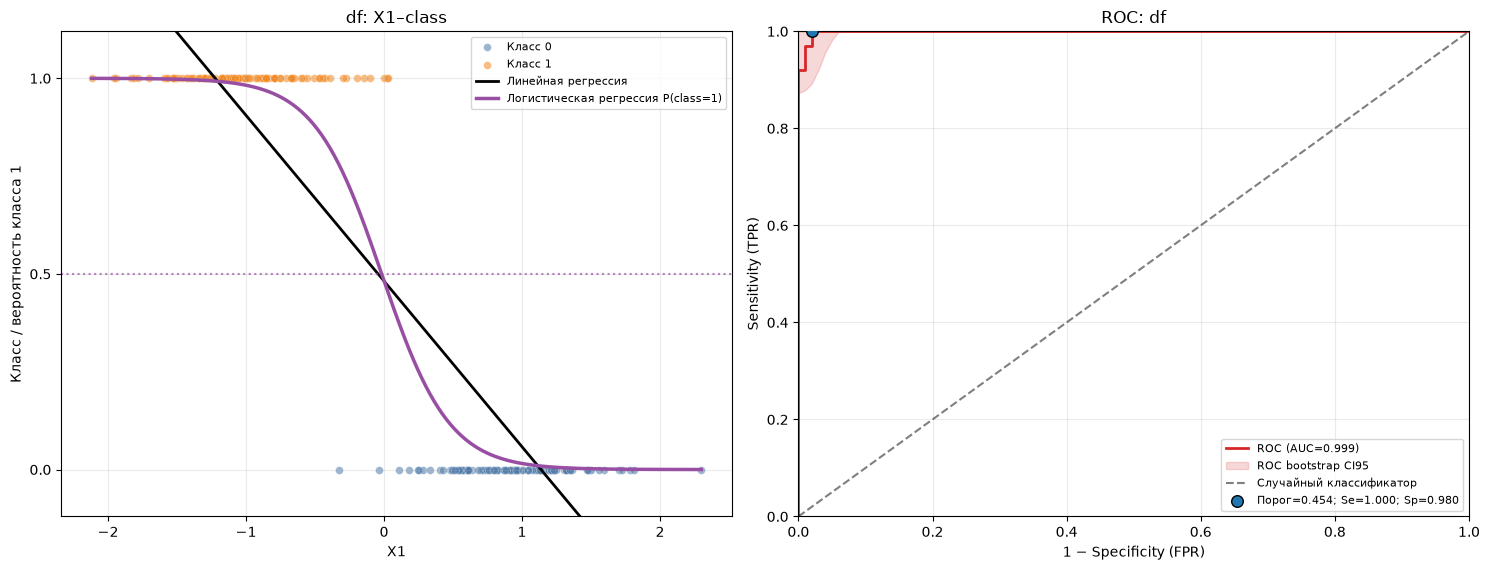

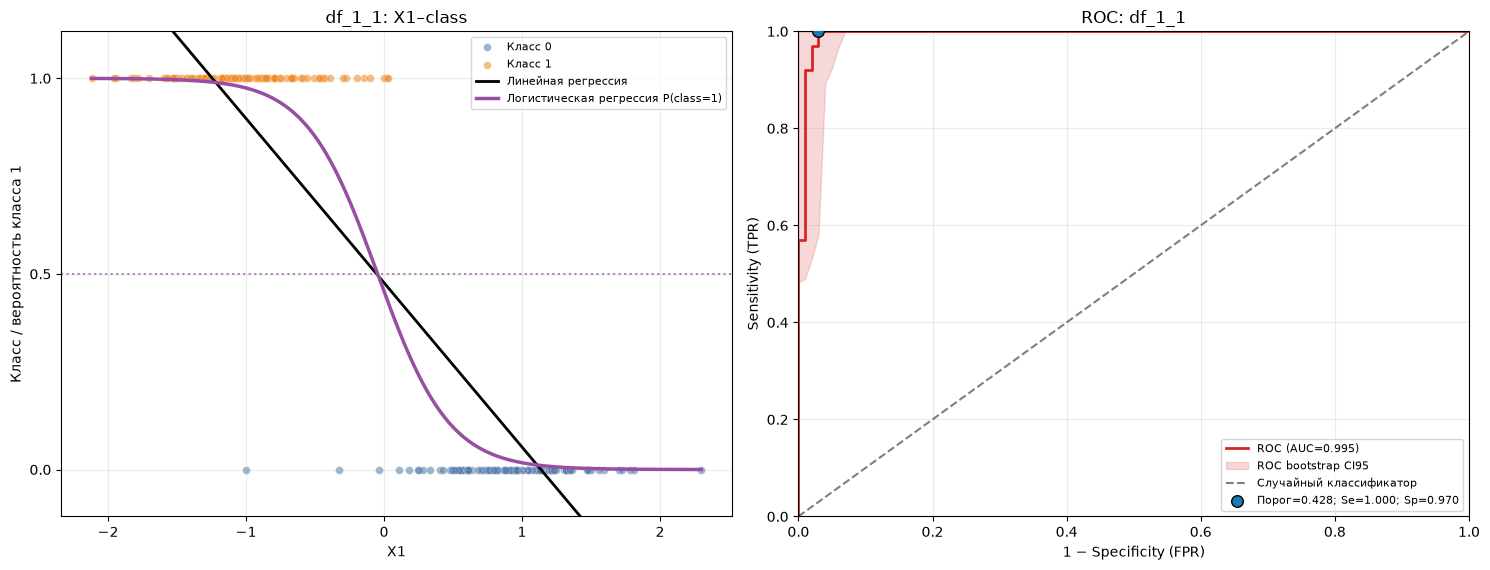

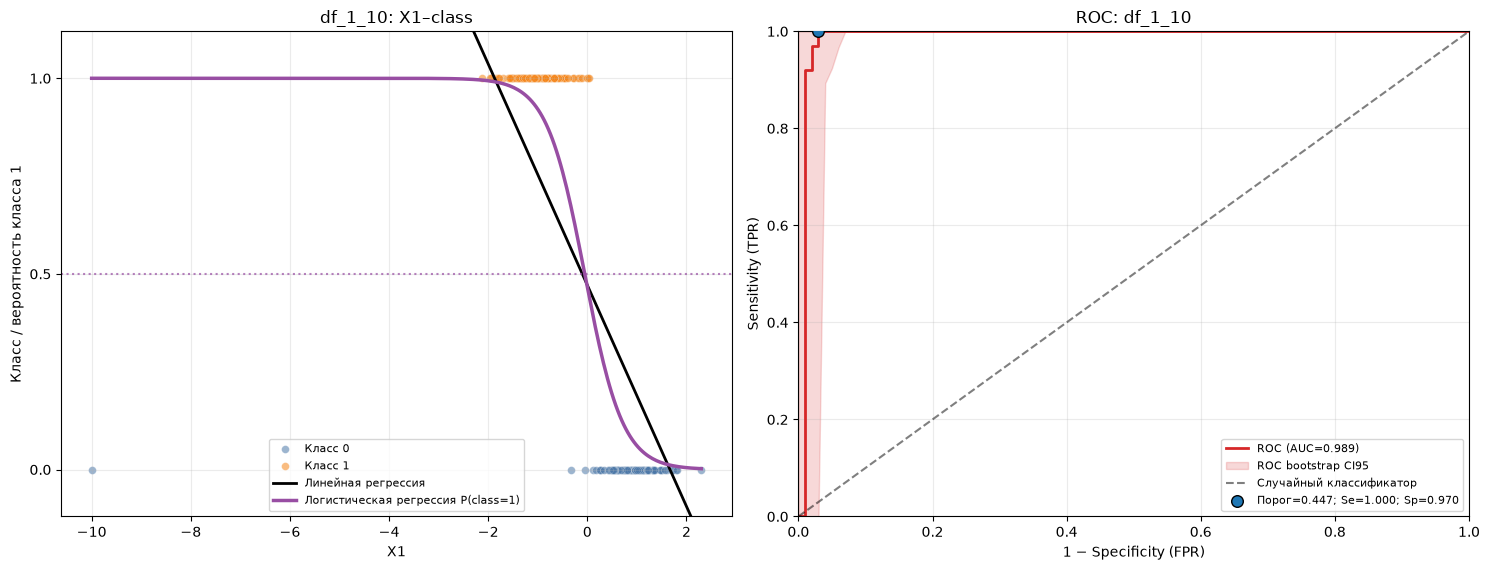

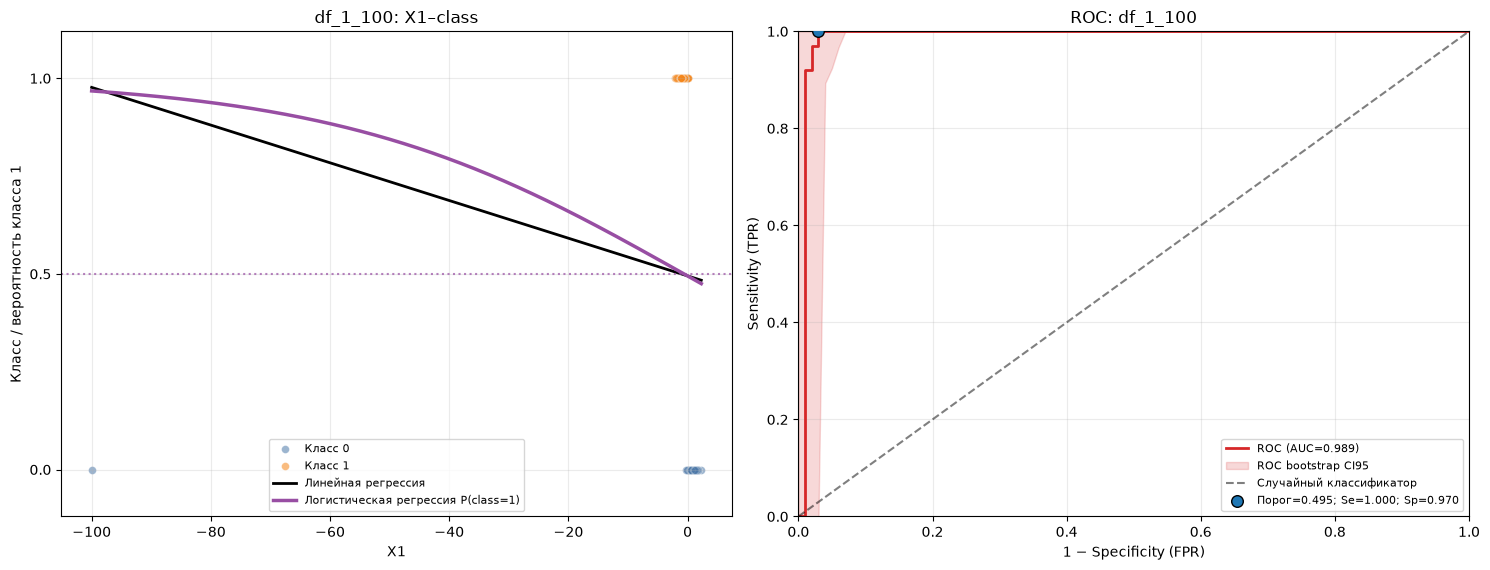

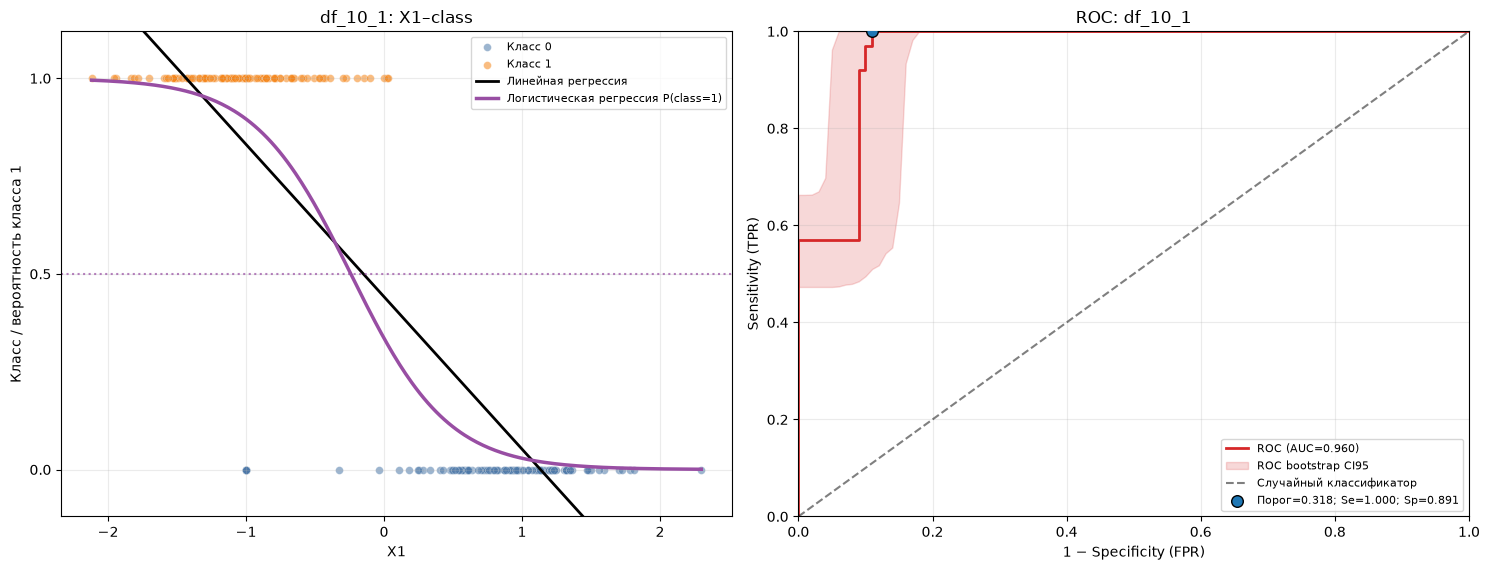

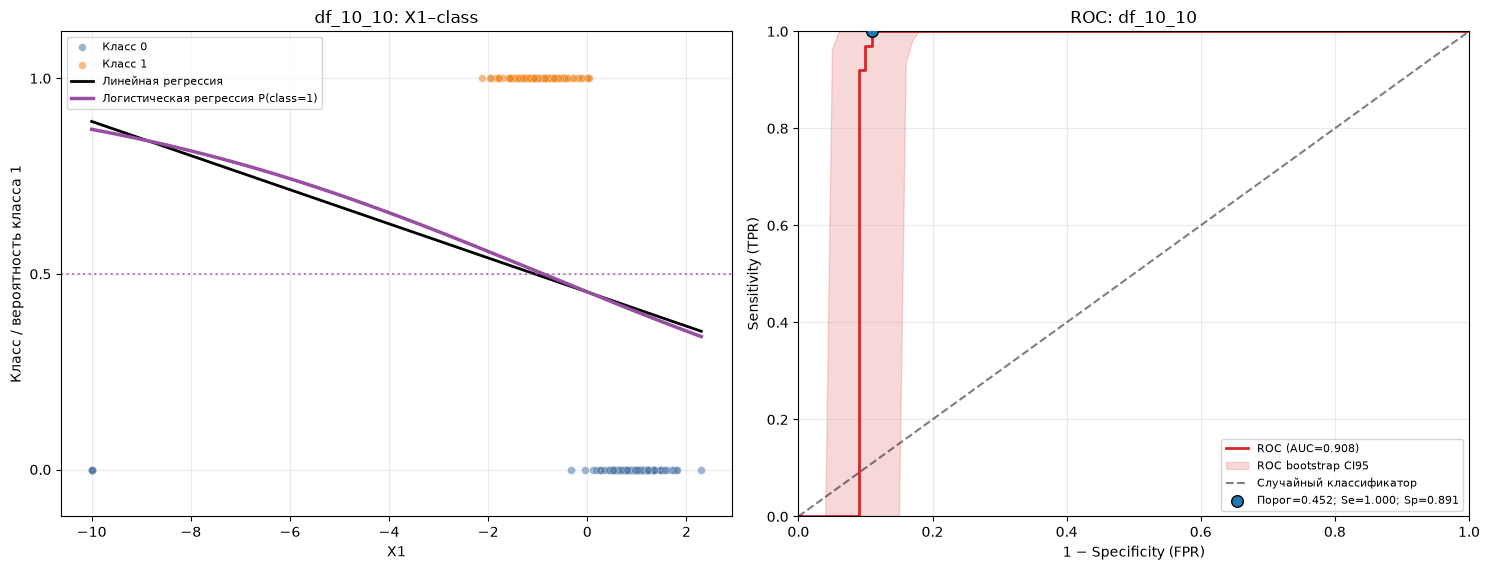

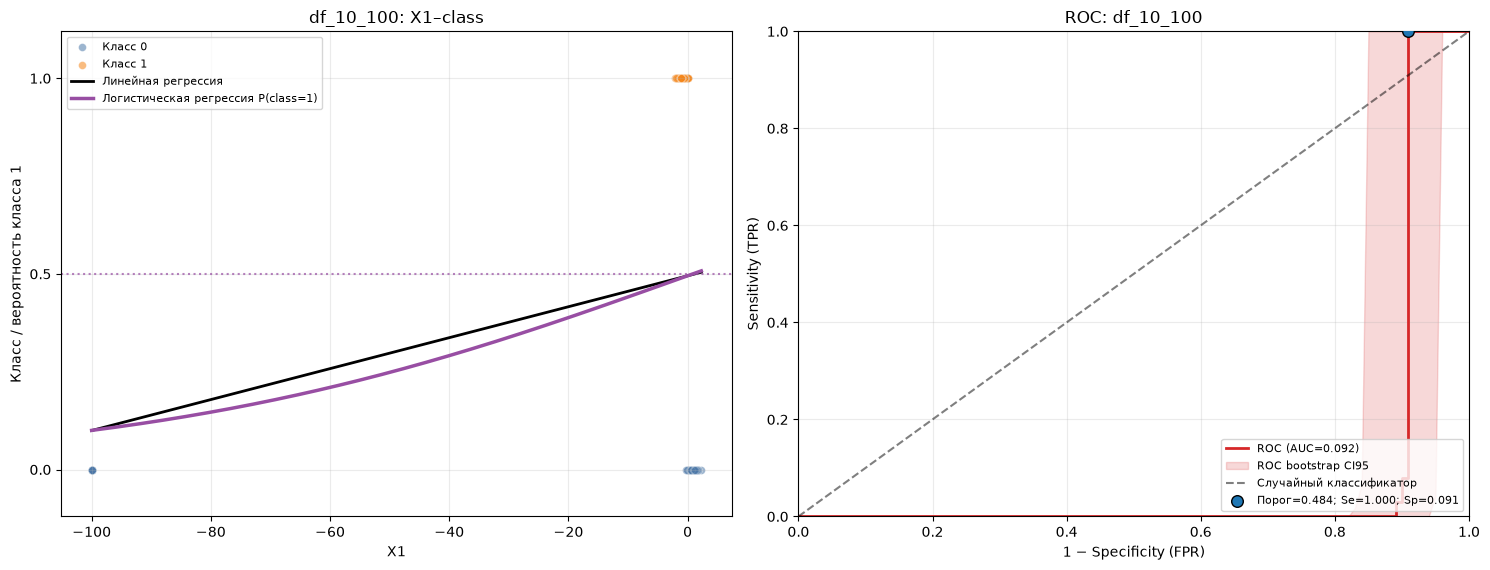

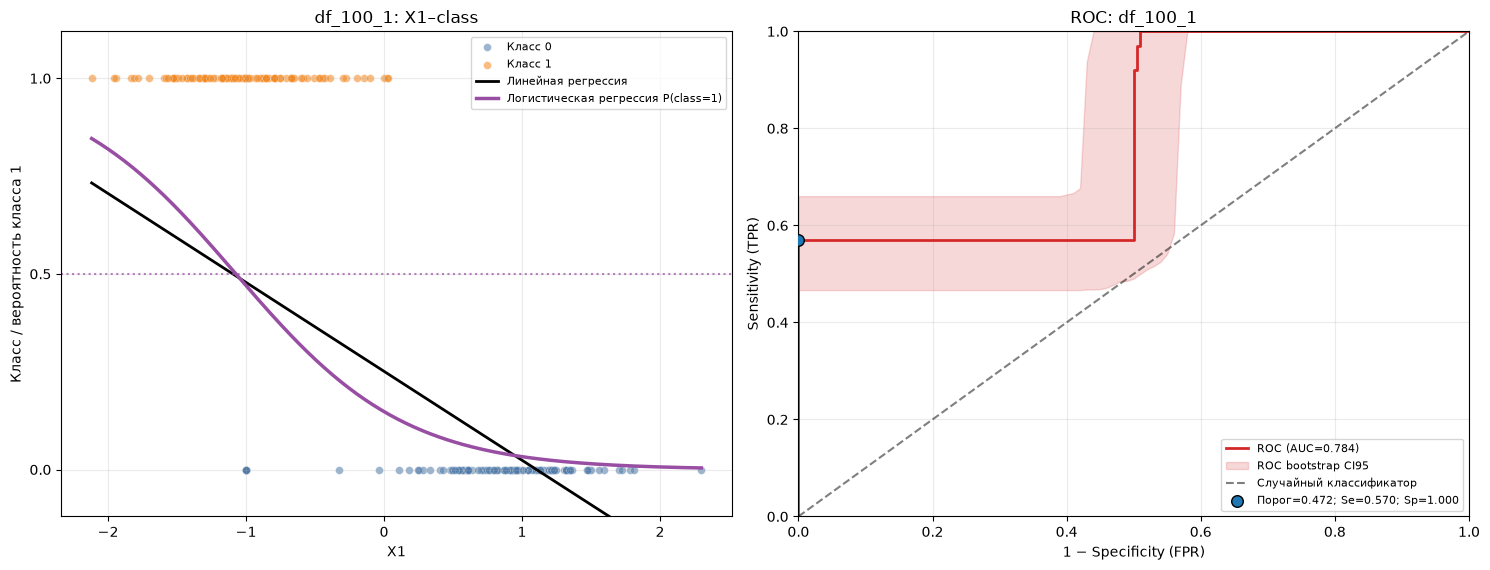

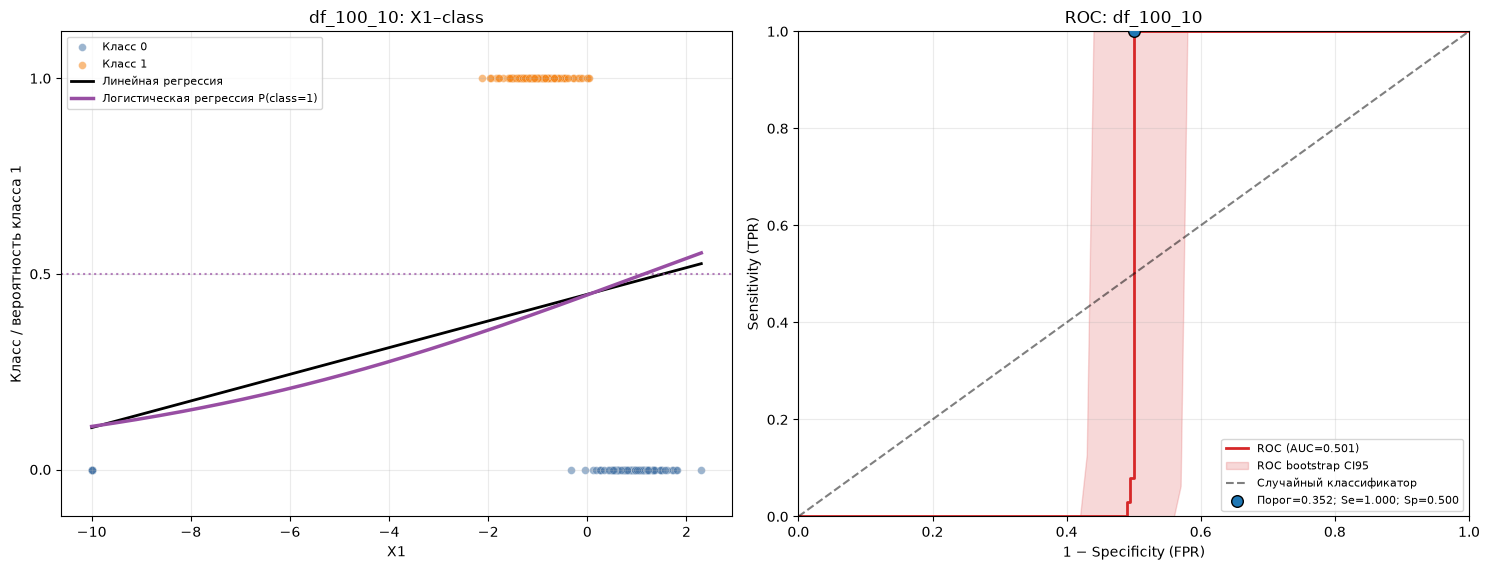

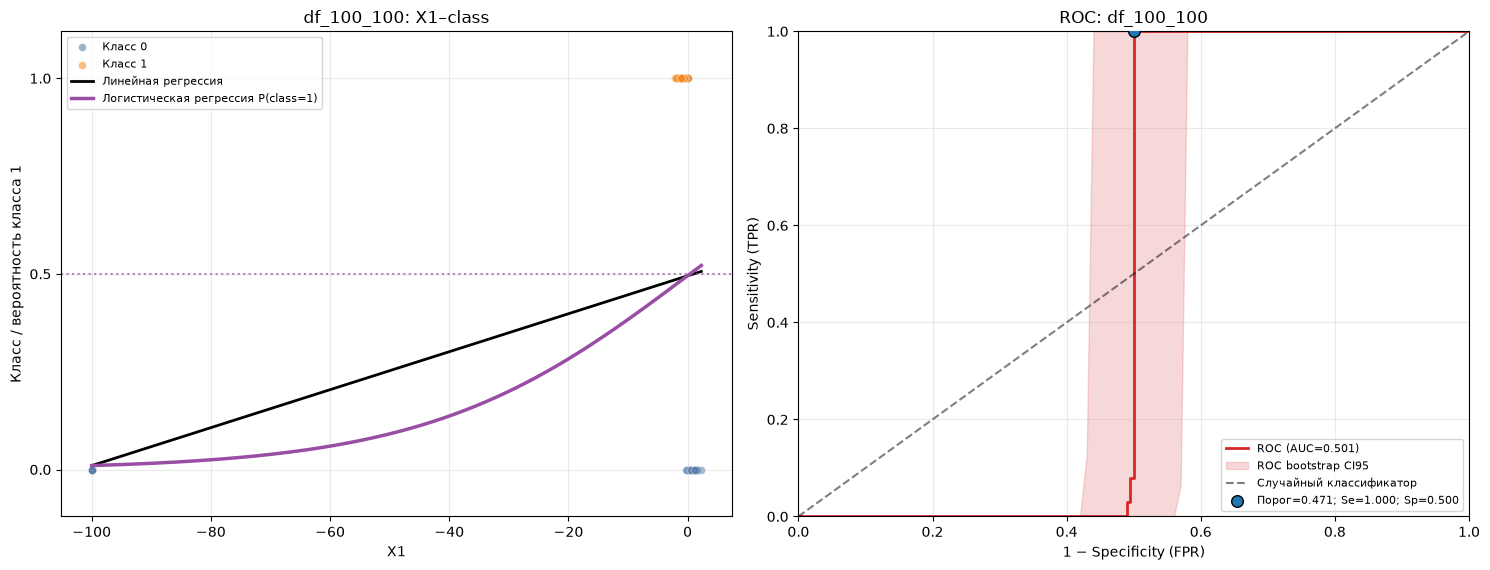

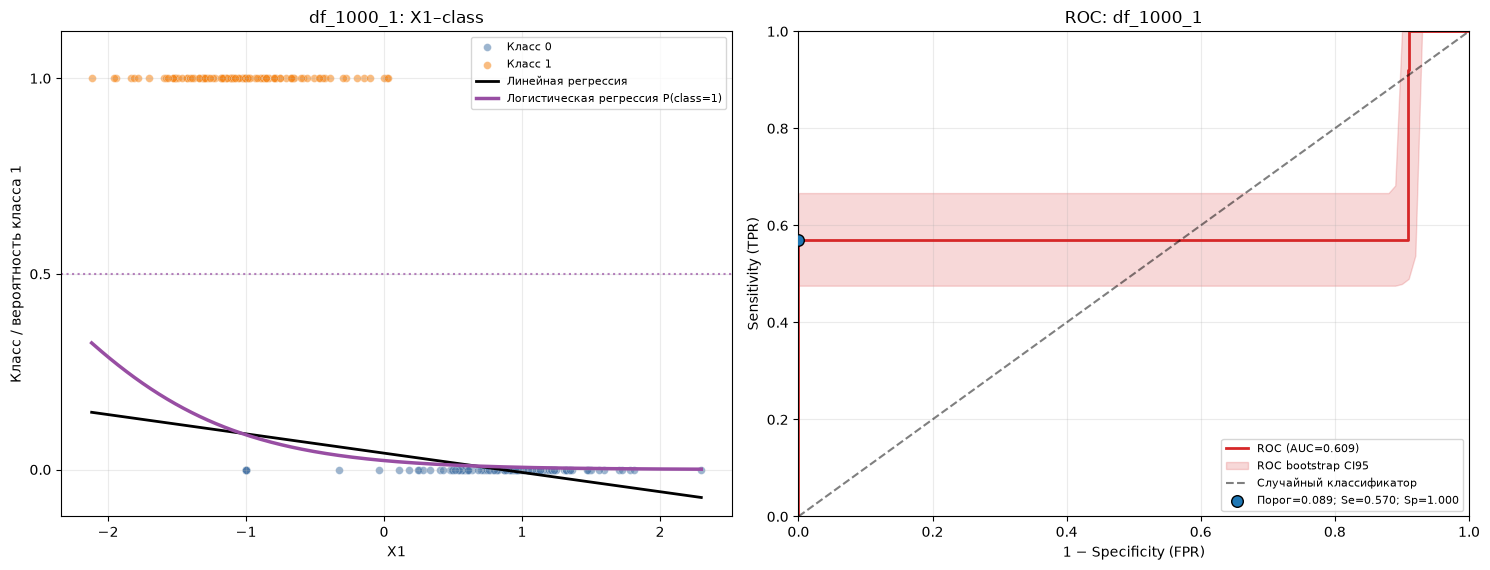

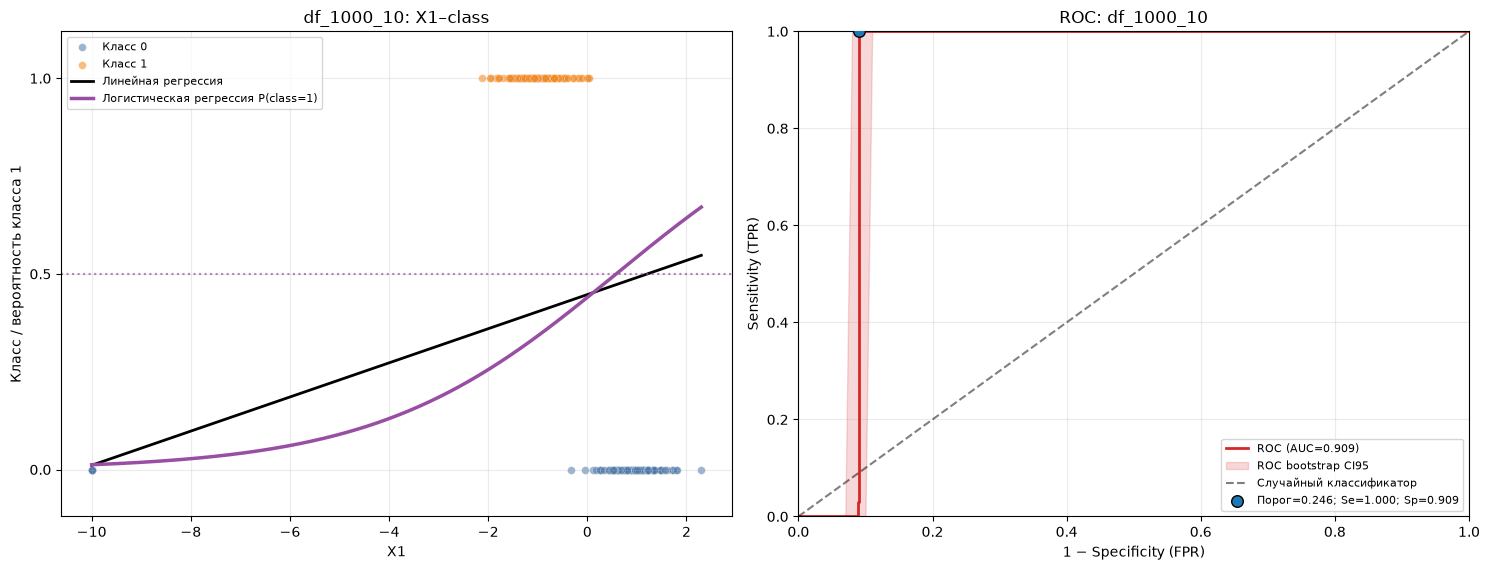

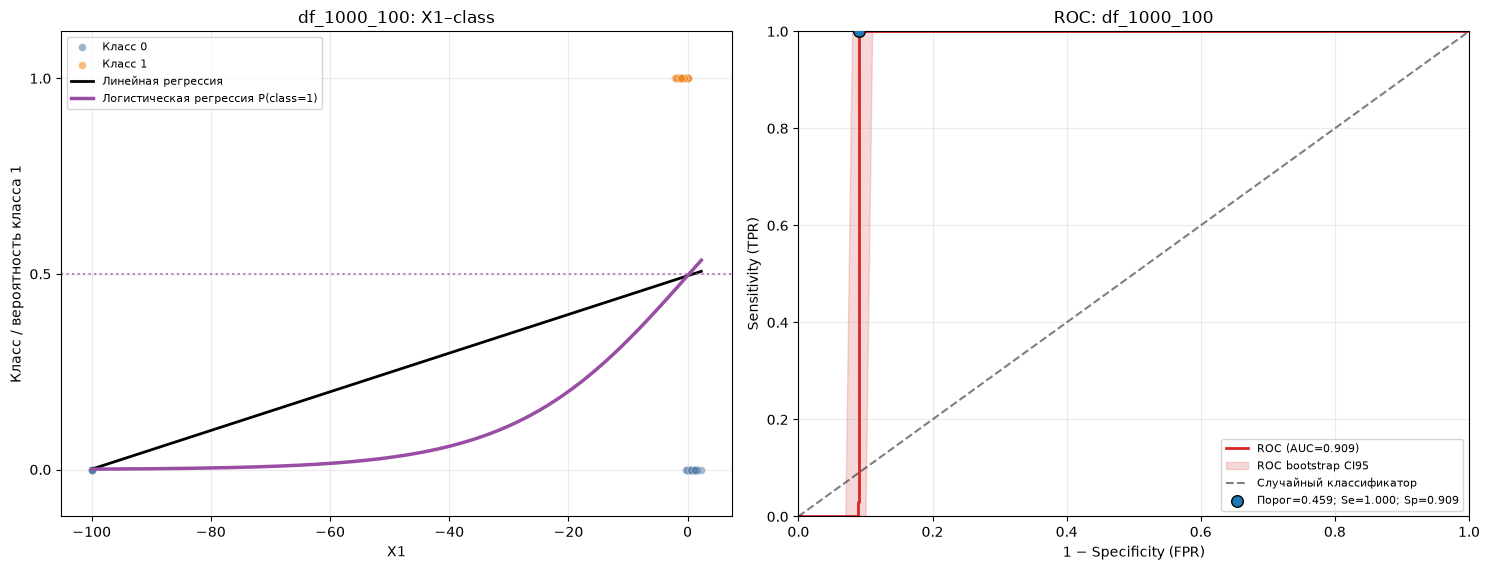

,Датасет,N,Порог,AUC,AUC CI95,Sensitivity,Sensitivity CI95,Specificity,Specificity CI95,Bootstrap valid
0,df,200,0.4536,0.9989,[0.996; 1.000],1.00,[1.000; 1.000],0.9800,[0.949; 1.000],1000
1,df_1_1,201,0.4282,0.9947,[0.984; 1.000],1.00,[1.000; 1.000],0.9703,[0.931; 1.000],1000
2,df_1_10,201,0.4473,0.9890,[0.966; 1.000],1.00,[1.000; 1.000],0.9703,[0.931; 1.000],1000
3,df_1_100,201,0.4945,0.9890,[0.966; 1.000],1.00,[1.000; 1.000],0.9703,[0.931; 1.000],1000
4,df_10_1,210,0.3179,0.9599,[0.930; 0.981],1.00,[1.000; 1.000],0.8909,[0.825; 0.945],1000
5,df_10_10,210,0.4523,0.9081,[0.848; 0.954],1.00,[1.000; 1.000],0.8909,[0.825; 0.945],1000
6,df_10_100,210,0.4837,0.0919,[0.046; 0.152],1.00,[1.000; 1.000],0.0909,[0.045; 0.152],1000
7,df_100_1,300,0.4717,0.7844,[0.725; 0.836],0.57,[0.467; 0.660],1.0000,[1.000; 1.000],1000
8,df_100_10,300,0.3515,0.5005,[0.428; 0.571],1.00,[1.000; 1.000],0.5000,[0.428; 0.570],1000
9,df_100_100,300,0.4713,0.5005,[0.428; 0.571],1.00,[1.000; 1.000],0.5000,[0.428; 0.570],1000


In [70]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

# Пользовательский выбор двух классов для визуализации и ROC-анализа.
# Например: SELECTED_CLASSES = [0, 2] или SELECTED_CLASSES = [1, 2].
SELECTED_CLASSES = [0, 1]
SELECTED_FEATURE = "X1"
N_BOOTSTRAP = 1000

AVAILABLE_CLASSES = sorted(df[CLASS_COL].unique())
if len(SELECTED_CLASSES) != 2 or len(set(SELECTED_CLASSES)) != 2:
    raise ValueError("SELECTED_CLASSES должен содержать ровно два разных класса")
if not set(SELECTED_CLASSES).issubset(AVAILABLE_CLASSES):
    raise ValueError(
        f"Неизвестный класс. Доступны: {AVAILABLE_CLASSES}; "
        f"выбраны: {SELECTED_CLASSES}"
    )
ROC_GRID = np.linspace(0, 1, 101)

# Список включает исходный df и все дополнительные df_A_B.
all_datasets_43 = {"df": df}
all_datasets_43.update({
    f"df_{A}_{B}": dataset
    for (A, B), dataset in sorted(datasets_A_B.items())
})

def bootstrap_roc_statistics(x, y, threshold, n_boot=1000, random_state=42):
    """Bootstrap CI95 для ROC-кривой, AUC и точки при фиксированном пороге."""
    rng_boot = np.random.default_rng(random_state)
    n = len(y)
    roc_samples, auc_samples = [], []
    sensitivity_samples, specificity_samples = [], []

    for _ in range(n_boot):
        indices = rng_boot.integers(0, n, size=n)
        y_boot = y[indices]
        score_boot = x[indices]
        # В bootstrap-выборке должны присутствовать оба класса.
        if np.unique(y_boot).size < 2:
            continue
        fpr_boot, tpr_boot, _ = roc_curve(y_boot, score_boot)
        roc_samples.append(np.interp(ROC_GRID, fpr_boot, tpr_boot))
        auc_samples.append(roc_auc_score(y_boot, score_boot))

        predicted = (score_boot >= threshold).astype(int)
        positives = y_boot == 1
        negatives = y_boot == 0
        sensitivity_samples.append(
            (predicted[positives] == 1).mean() if positives.any() else np.nan
        )
        specificity_samples.append(
            (predicted[negatives] == 0).mean() if negatives.any() else np.nan
        )

    roc_samples = np.asarray(roc_samples)
    ci = lambda values: np.nanpercentile(values, [2.5, 97.5])
    return {
        "roc_low": np.nanpercentile(roc_samples, 2.5, axis=0),
        "roc_high": np.nanpercentile(roc_samples, 97.5, axis=0),
        "auc_ci": ci(auc_samples),
        "sensitivity_ci": ci(sensitivity_samples),
        "specificity_ci": ci(specificity_samples),
        "n_valid_bootstrap": len(auc_samples),
    }

results_43 = []
for dataset_name, dataset in all_datasets_43.items():
    subset = dataset[dataset[CLASS_COL].isin(SELECTED_CLASSES)].dropna(
        subset=[SELECTED_FEATURE, CLASS_COL]
    )
    x = subset[SELECTED_FEATURE].to_numpy(dtype=float)
    y_original = subset[CLASS_COL].to_numpy(dtype=int)
    class_to_binary = {class_id: i for i, class_id in enumerate(SELECTED_CLASSES)}
    y = np.array([class_to_binary[class_id] for class_id in y_original], dtype=int)
    order = np.argsort(x)
    x_sorted = x[order]
    y_sorted = y[order]

    positive_class = SELECTED_CLASSES[1]

    # Линейная регрессия class ~ X.
    linear_slope, linear_intercept = np.polyfit(x, y, deg=1)

    # Логистическая регрессия class ~ X.
    logistic = LogisticRegression(solver="lbfgs", random_state=42)
    logistic.fit(x.reshape(-1, 1), y)
    x_grid = np.linspace(x.min(), x.max(), 300)
    probability_grid = logistic.predict_proba(x_grid.reshape(-1, 1))[:, 1]
    scores = logistic.predict_proba(x.reshape(-1, 1))[:, 1]

    fpr, tpr, thresholds = roc_curve(y, scores)
    auc = roc_auc_score(y, scores)
    # Оптимальный порог: максимум Sensitivity + Specificity - 1.
    finite = np.isfinite(thresholds)
    youden_index = tpr[finite] - fpr[finite]
    best_position = np.flatnonzero(finite)[np.argmax(youden_index)]
    threshold = thresholds[best_position]
    sensitivity = tpr[best_position]
    specificity = 1 - fpr[best_position]
    bootstrap = bootstrap_roc_statistics(
        scores, y, threshold, n_boot=N_BOOTSTRAP, random_state=42
    )

    fig, (ax_reg, ax_roc) = plt.subplots(1, 2, figsize=(15, 5.8))

    # Левая часть: данные и обе регрессии в пространстве X-Y.
    for class_id in SELECTED_CLASSES:
        mask = y_original == class_id
        ax_reg.scatter(
            x[mask], y[mask], s=32, alpha=0.55,
            color=CLASS_PALETTE[class_id], label=f"Класс {class_id}",
            edgecolors="white", linewidths=0.35
        )
    ax_reg.plot(
        x_grid, linear_slope * x_grid + linear_intercept,
        color="black", linewidth=2, label="Линейная регрессия"
    )
    ax_reg.plot(
        x_grid, probability_grid, color="#984EA3", linewidth=2.5,
        label=f"Логистическая регрессия P(class={positive_class})"
    )
    ax_reg.axhline(0.5, color="#984EA3", linestyle=":", alpha=0.7)
    ax_reg.set(
        title=f"{dataset_name}: {SELECTED_FEATURE}–class",
        xlabel=SELECTED_FEATURE, ylabel=f"Класс / вероятность класса {positive_class}",
        yticks=[0, 0.5, 1], ylim=(-0.12, 1.12)
    )
    ax_reg.grid(alpha=0.25)
    ax_reg.legend(fontsize=8)

    # Правая часть: ROC с оптимальной точкой и bootstrap CI95.
    ax_roc.plot(fpr, tpr, color="#D62728", linewidth=2, label=f"ROC (AUC={auc:.3f})")
    ax_roc.fill_between(
        ROC_GRID, bootstrap["roc_low"], bootstrap["roc_high"],
        color="#D62728", alpha=0.18, label="ROC bootstrap CI95"
    )
    ax_roc.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Случайный классификатор")
    ax_roc.scatter(
        fpr[best_position], tpr[best_position], s=70,
        color="#1F77B4", edgecolors="black", zorder=5,
        label=(f"Порог={threshold:.3f}; Se={sensitivity:.3f}; "
               f"Sp={specificity:.3f}")
    )
    ax_roc.set(
        title=f"ROC: {dataset_name}", xlabel="1 − Specificity (FPR)",
        ylabel="Sensitivity (TPR)", xlim=(0, 1), ylim=(0, 1)
    )
    ax_roc.grid(alpha=0.25)
    ax_roc.legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()

    results_43.append({
        "Датасет": dataset_name,
        "N": len(y),
        "Порог": threshold,
        "AUC": auc,
        "AUC CI95": f"[{bootstrap['auc_ci'][0]:.3f}; {bootstrap['auc_ci'][1]:.3f}]",
        "Sensitivity": sensitivity,
        "Sensitivity CI95": (f"[{bootstrap['sensitivity_ci'][0]:.3f}; "
                              f"{bootstrap['sensitivity_ci'][1]:.3f}]"),
        "Specificity": specificity,
        "Specificity CI95": (f"[{bootstrap['specificity_ci'][0]:.3f}; "
                              f"{bootstrap['specificity_ci'][1]:.3f}]"),
        "Bootstrap valid": bootstrap["n_valid_bootstrap"],
    })

results_43 = pd.DataFrame(results_43)
display(results_43.round(4))

## [4.4] Множественная линейная регрессия и одномерные датасеты

Для выбранной пары классов (пользователь может выбирать) на первых четырёх признаках строится модель множественной линейной регрессии:

$$Y = b_0 + b_1X_1 + b_2X_2 + b_3X_3 + b_4X_4,$$

где `Y` — принадлежность к классу. Полученное уравнение применяется к исходному `df` и каждому `df_A_B`. Для каждого набора создаётся новый датасет `logdf...` с единственным количественным признаком `X` и переменной класса `Y`.

In [71]:
from sklearn.linear_model import LinearRegression

REGRESSION_CLASSES_44 = [0, 1]
REGRESSION_FEATURES_44 = FEATURES[:4]
if len(REGRESSION_CLASSES_44) != 2 or len(set(REGRESSION_CLASSES_44)) != 2:
    raise ValueError("REGRESSION_CLASSES_44 должен содержать ровно два разных класса")
CLASS_TO_BINARY_44 = {class_id: i for i, class_id in enumerate(REGRESSION_CLASSES_44)}

# Уравнение оценивается на выбранной паре классов исходного df.
base_44 = df[df[CLASS_COL].isin(REGRESSION_CLASSES_44)].dropna(
    subset=REGRESSION_FEATURES_44 + [CLASS_COL]
)
X_train_44 = base_44[REGRESSION_FEATURES_44]
y_train_44 = base_44[CLASS_COL].map(CLASS_TO_BINARY_44).astype(float)

multiple_linear_model_44 = LinearRegression()
multiple_linear_model_44.fit(X_train_44, y_train_44)

intercept_44 = float(multiple_linear_model_44.intercept_)
coefficients_44 = dict(zip(
    REGRESSION_FEATURES_44,
    multiple_linear_model_44.coef_.astype(float)
))

equation_44 = (
    f"Y = {intercept_44:.6f} "
    + " ".join(
        f"{coefficient:+.6f}·{feature}"
        for feature, coefficient in coefficients_44.items()
    )
)
print("Уравнение множественной линейной регрессии:")
print(equation_44)
print(f"R² на df для классов {REGRESSION_CLASSES_44}: "
      f"{multiple_linear_model_44.score(X_train_44, y_train_44):.4f}")

# Словари хранят все производные наборы, а globals() создаёт переменные
# logdf и logdf_A_B с именами, соответствующими исходным наборам.
logdatasets_A_B = {}

def make_log_dataset_44(dataset):
    subset = dataset[dataset[CLASS_COL].isin(REGRESSION_CLASSES_44)].dropna(
        subset=REGRESSION_FEATURES_44 + [CLASS_COL]
    )
    linear_score = multiple_linear_model_44.predict(
        subset[REGRESSION_FEATURES_44]
    )
    return pd.DataFrame({
        "X": linear_score,
        # Для ROC и логистической регрессии выбранные классы кодируются как 0 и 1.
        "Y": subset[CLASS_COL].map(CLASS_TO_BINARY_44).to_numpy(dtype=int),
    }, index=subset.index).reset_index(drop=True)

logdf = make_log_dataset_44(df)
for (A, B), dataset in sorted(datasets_A_B.items()):
    log_dataset_name = f"logdf_{A}_{B}"
    log_dataset = make_log_dataset_44(dataset)
    logdatasets_A_B[(A, B)] = log_dataset
    globals()[log_dataset_name] = log_dataset

log_control_44 = [{
    "Датасет": "logdf",
    "Объектов": len(logdf),
    "Класс 0": int((logdf["Y"] == 0).sum()),
    "Класс 1": int((logdf["Y"] == 1).sum()),
    "Признаки": logdf.columns.tolist(),
}]
for (A, B), log_dataset in sorted(logdatasets_A_B.items()):
    log_control_44.append({
        "Датасет": f"logdf_{A}_{B}",
        "Объектов": len(log_dataset),
        "Класс 0": int((log_dataset["Y"] == 0).sum()),
        "Класс 1": int((log_dataset["Y"] == 1).sum()),
        "Признаки": log_dataset.columns.tolist(),
    })

print("\nКонтроль созданных датасетов:")
display(pd.DataFrame(log_control_44))
print("\nПример logdf:")
display(logdf.head())

Уравнение множественной линейной регрессии:
Y = 0.490635 -0.110657·X1 -0.126543·X2 -0.100756·X3 -0.121566·X4
R² на df для классов [0, 1]: 0.9498

Контроль созданных датасетов:


,Датасет,Объектов,Класс 0,Класс 1,Признаки
0,logdf,200,100,100,"[X, Y]"
1,logdf_1_1,201,101,100,"[X, Y]"
2,logdf_1_10,201,101,100,"[X, Y]"
3,logdf_1_100,201,101,100,"[X, Y]"
4,logdf_10_1,210,110,100,"[X, Y]"
5,logdf_10_10,210,110,100,"[X, Y]"
6,logdf_10_100,210,110,100,"[X, Y]"
7,logdf_100_1,300,200,100,"[X, Y]"
8,logdf_100_10,300,200,100,"[X, Y]"
9,logdf_100_100,300,200,100,"[X, Y]"



Пример logdf:


,X,Y
0,-0.010062,0
1,-0.001691,0
2,0.030261,0
3,0.028384,0
4,0.013382,0


## [4.5] Регрессии и ROC-анализ одномерных `logdf`

Для каждого набора `logdf` и `logdf_A_B` в пространстве `X–Y` строятся простая линейная регрессия, логистическая регрессия и ROC-кривая. На ROC-графике отмечается точка классификации, выбранная по индексу Юдена, и bootstrap-доверительный интервал CI95 для ROC-кривой (`n=1000`).

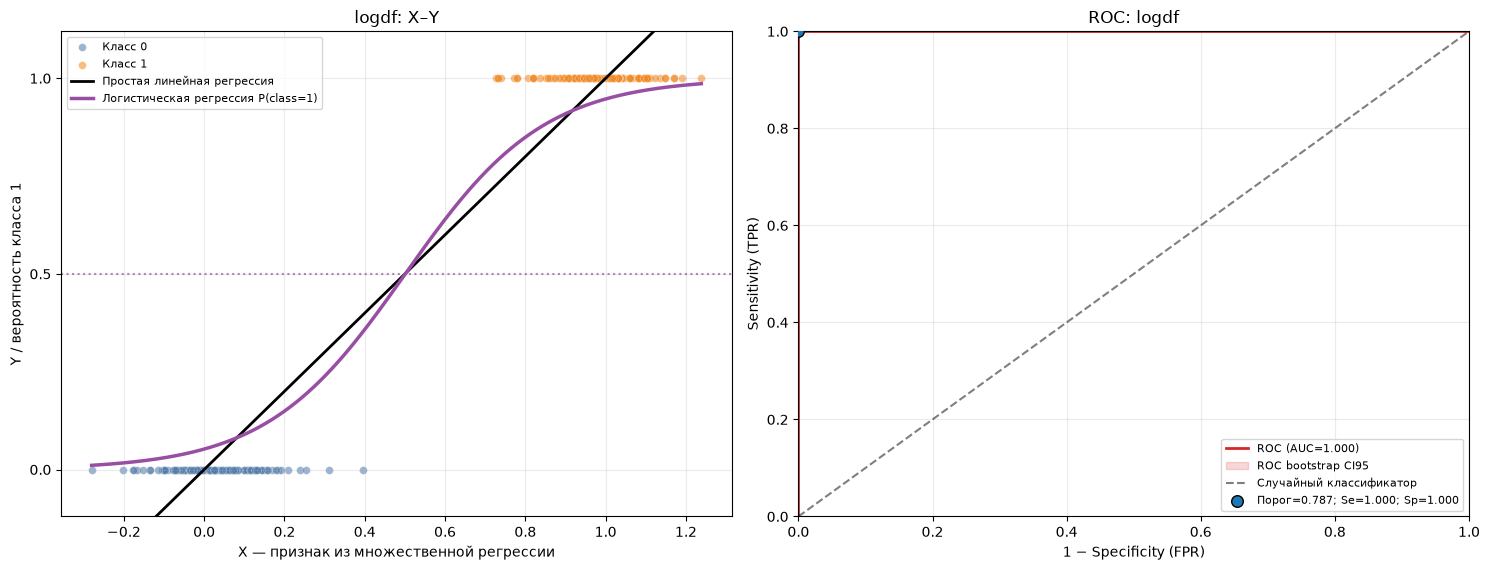

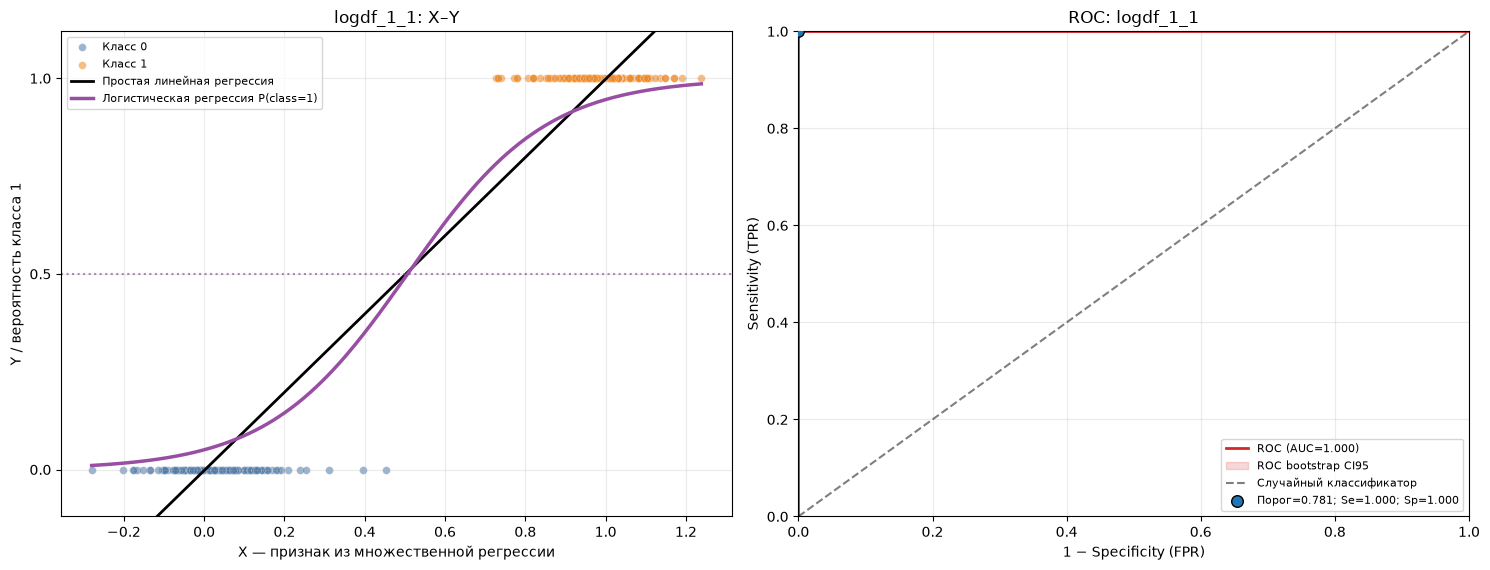

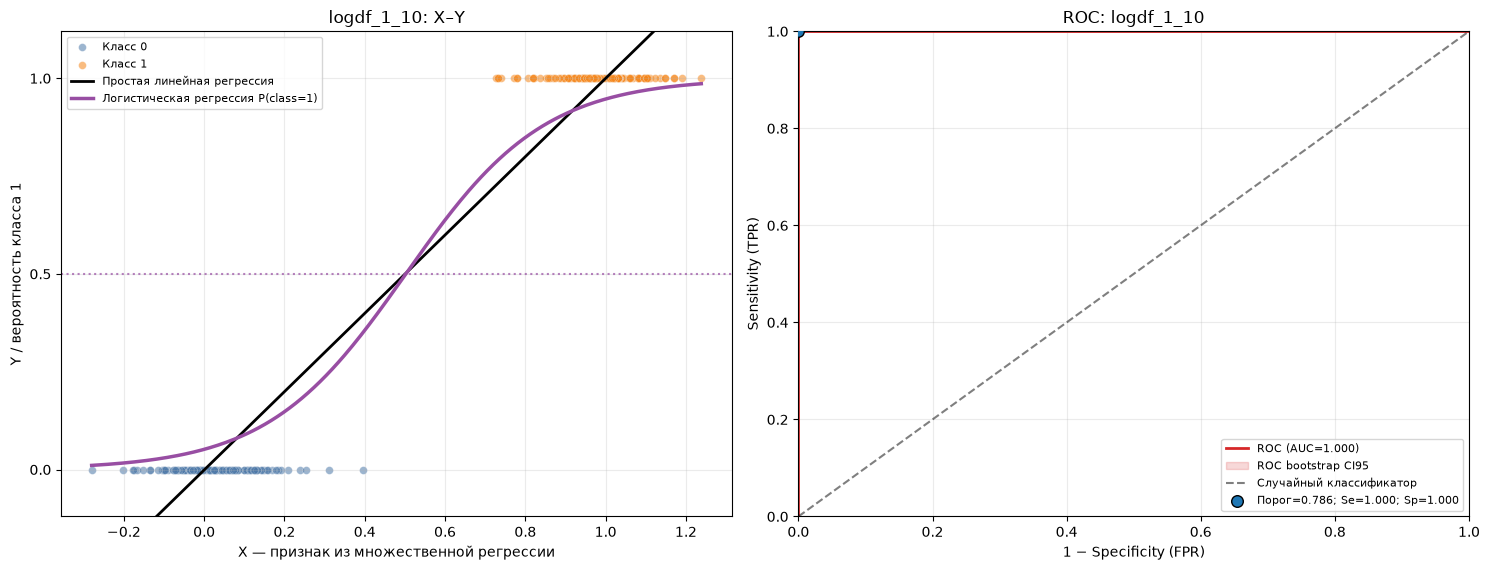

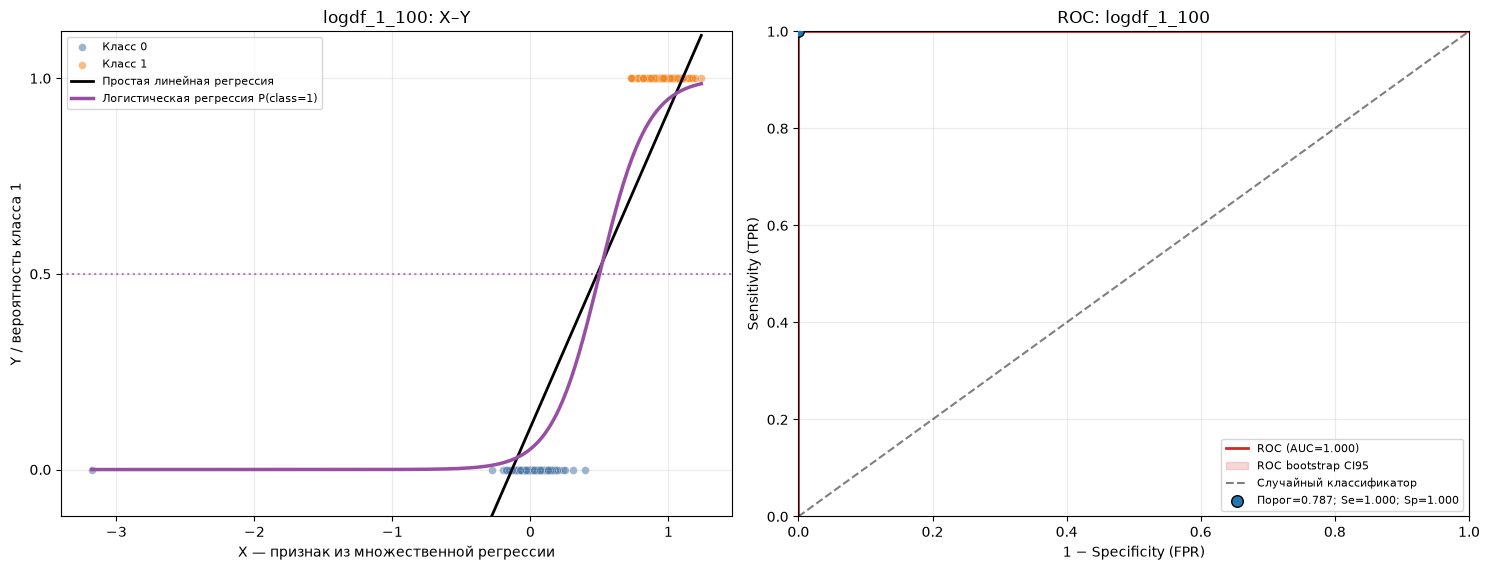

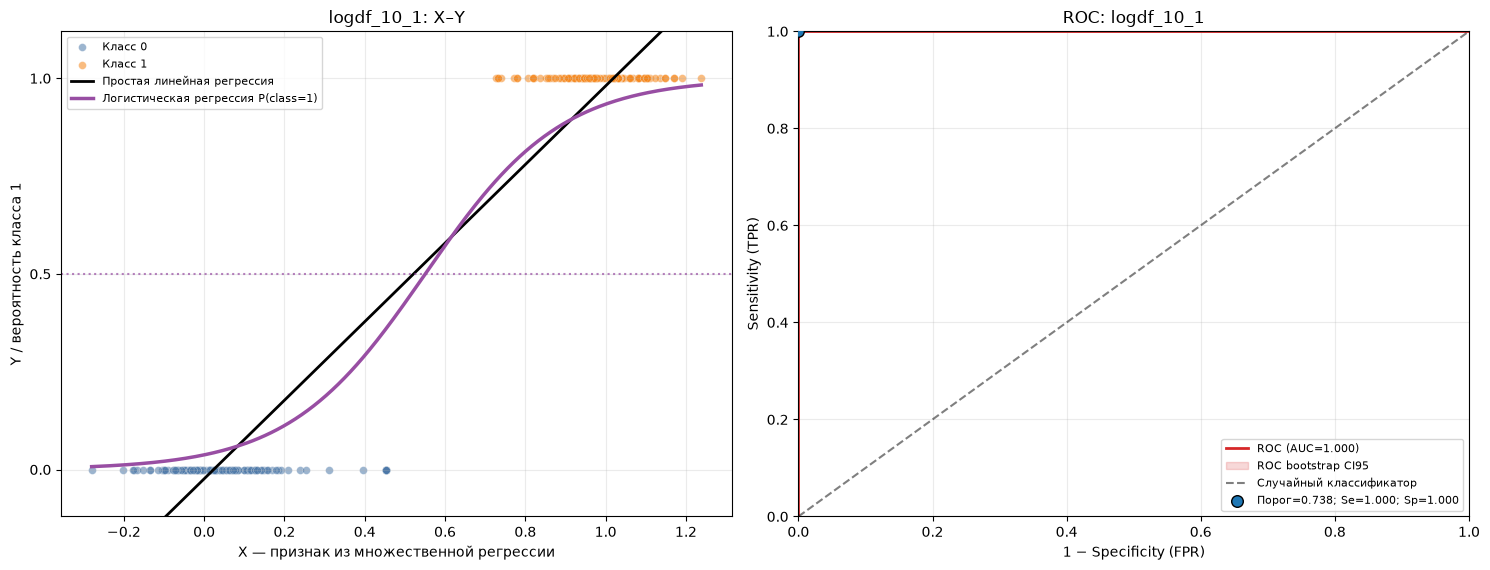

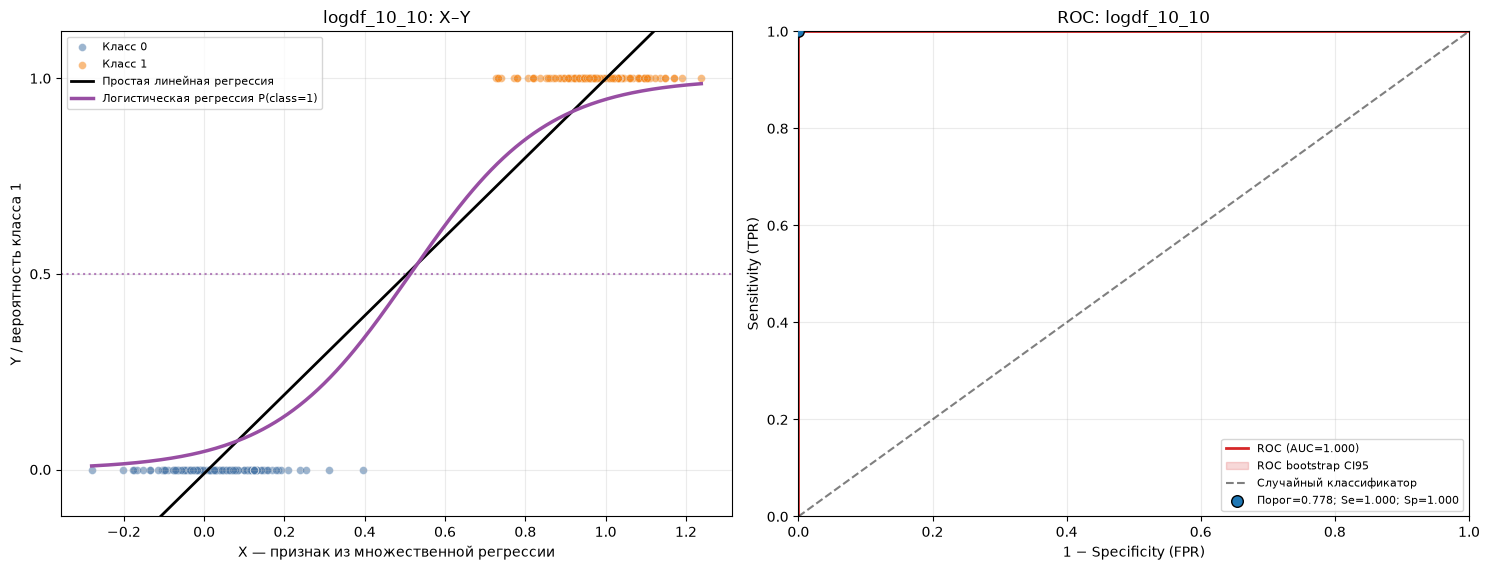

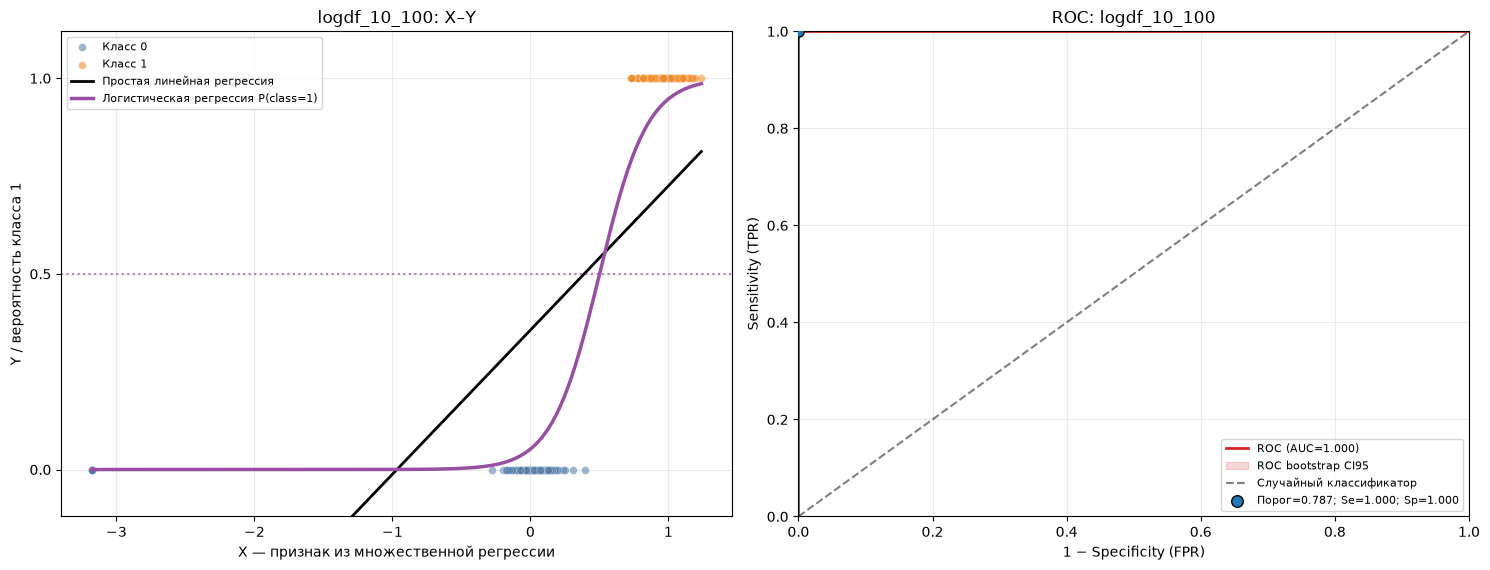

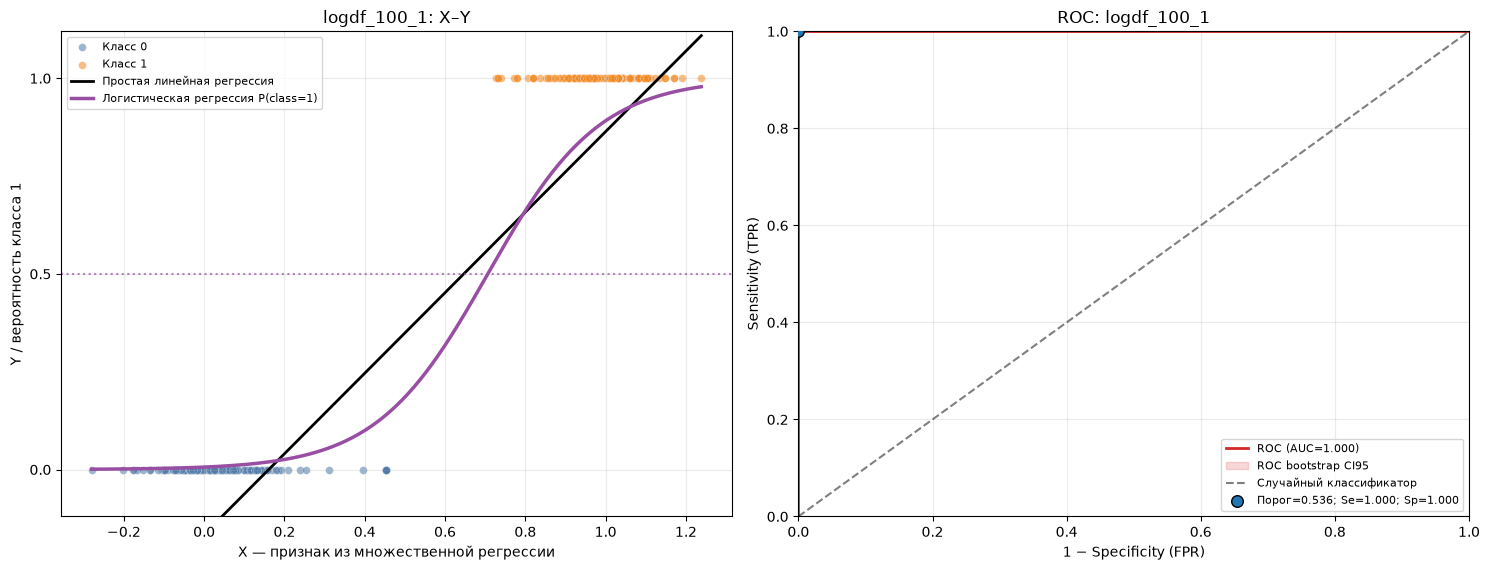

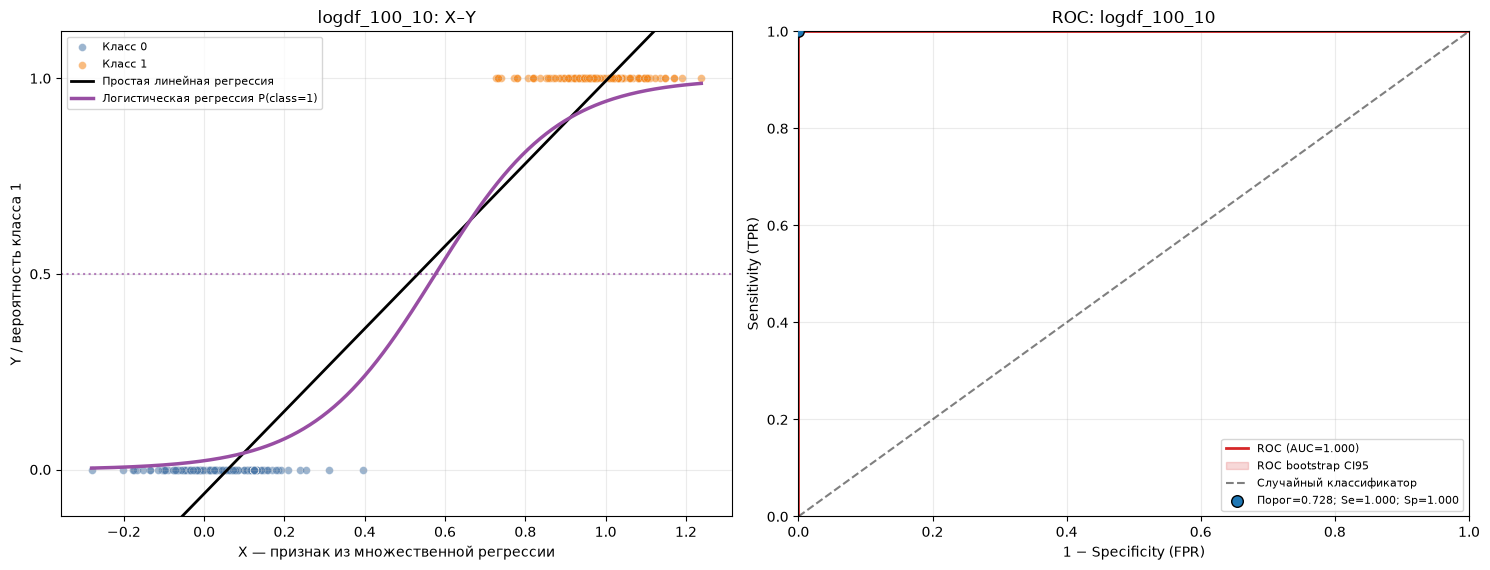

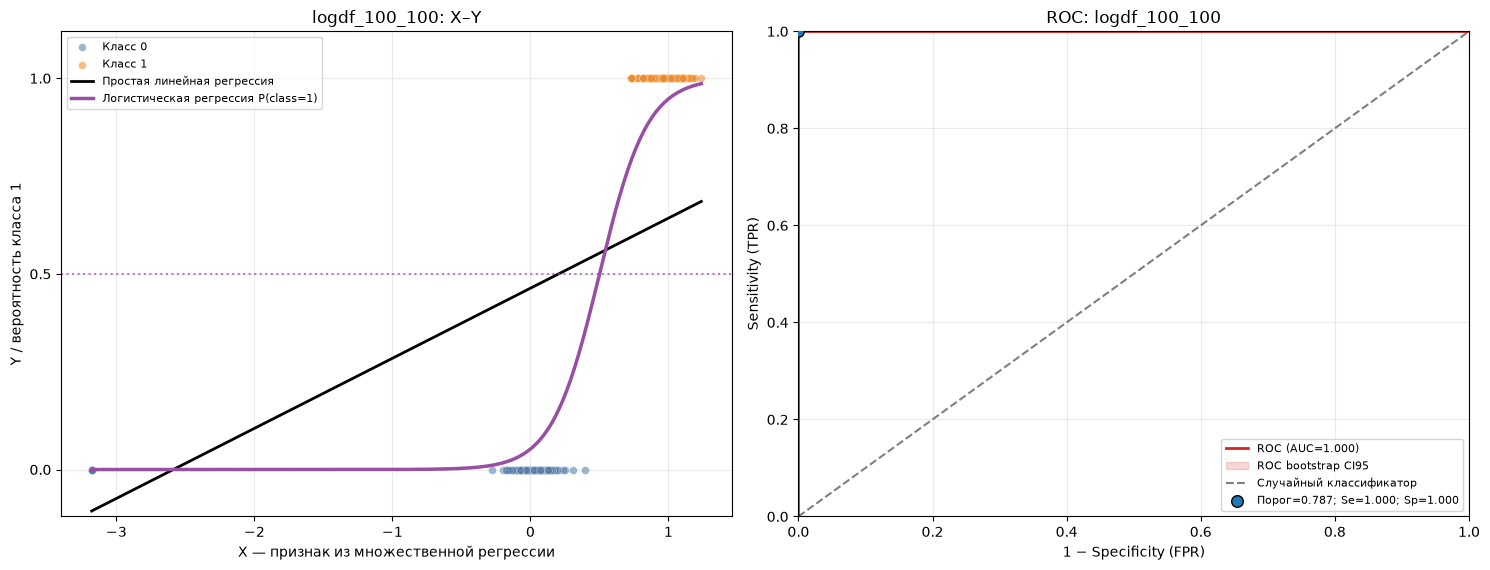

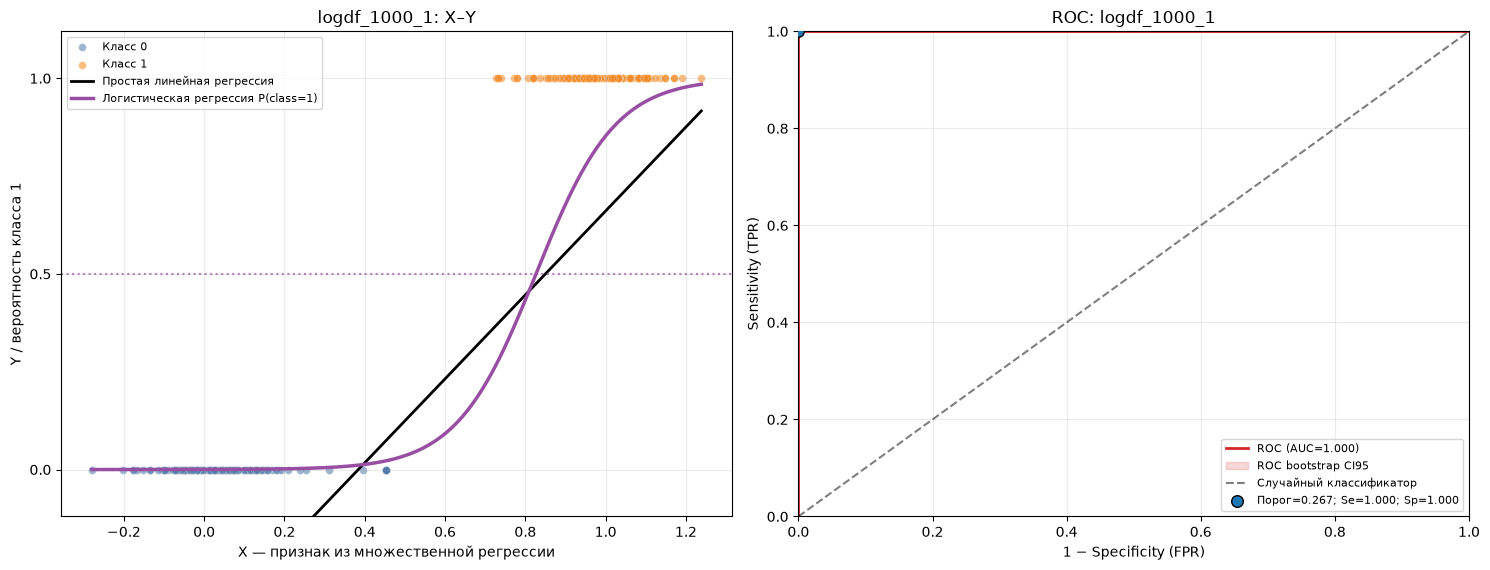

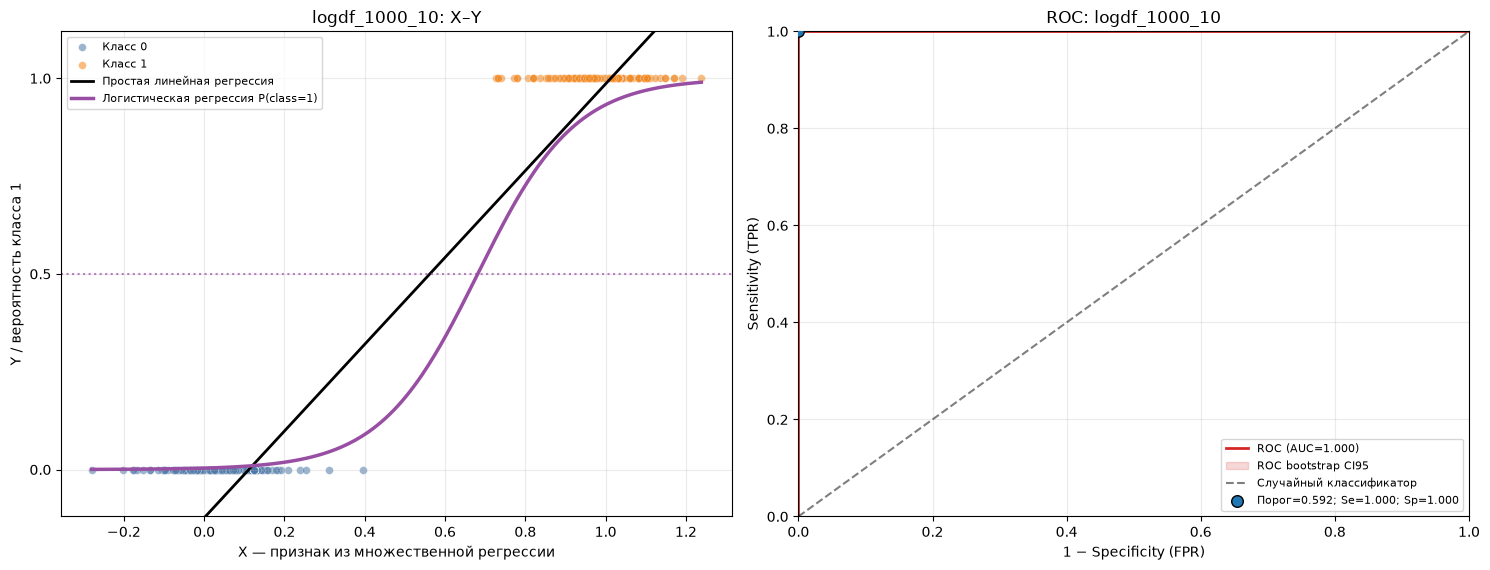

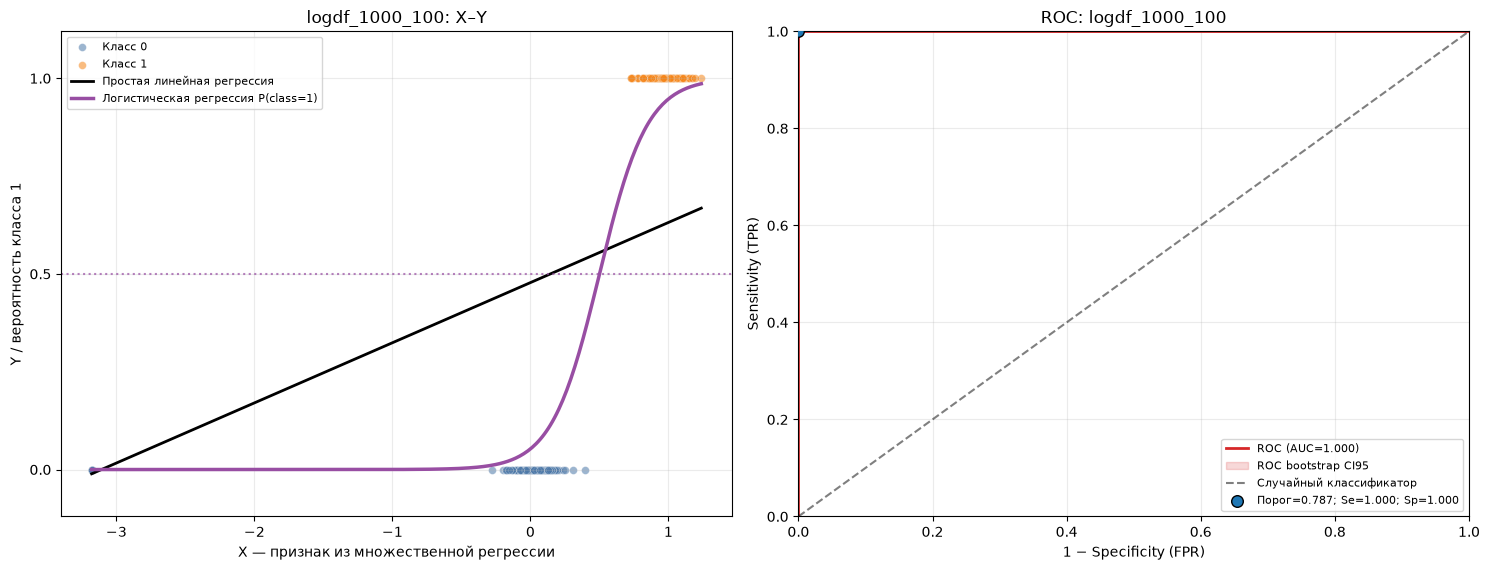

Итоговые оценки для logdf и logdf_A_B:


,Датасет,N,Порог,AUC,AUC CI95,Sensitivity,Sensitivity CI95,Specificity,Specificity CI95,Bootstrap valid
0,logdf,200,0.7867,1.0,[1.000; 1.000],1.0,[1.000; 1.000],1.0,[1.000; 1.000],1000
1,logdf_1_1,201,0.7813,1.0,[1.000; 1.000],1.0,[1.000; 1.000],1.0,[1.000; 1.000],1000
2,logdf_1_10,201,0.7858,1.0,[1.000; 1.000],1.0,[1.000; 1.000],1.0,[1.000; 1.000],1000
3,logdf_1_100,201,0.7866,1.0,[1.000; 1.000],1.0,[1.000; 1.000],1.0,[1.000; 1.000],1000
4,logdf_10_1,210,0.7382,1.0,[1.000; 1.000],1.0,[1.000; 1.000],1.0,[1.000; 1.000],1000
5,logdf_10_10,210,0.7781,1.0,[1.000; 1.000],1.0,[1.000; 1.000],1.0,[1.000; 1.000],1000
6,logdf_10_100,210,0.7867,1.0,[1.000; 1.000],1.0,[1.000; 1.000],1.0,[1.000; 1.000],1000
7,logdf_100_1,300,0.5361,1.0,[1.000; 1.000],1.0,[1.000; 1.000],1.0,[1.000; 1.000],1000
8,logdf_100_10,300,0.7275,1.0,[1.000; 1.000],1.0,[1.000; 1.000],1.0,[1.000; 1.000],1000
9,logdf_100_100,300,0.7869,1.0,[1.000; 1.000],1.0,[1.000; 1.000],1.0,[1.000; 1.000],1000


In [72]:
# Список включает logdf и все logdf_A_B, созданные в пункте [4.4].
all_logdatasets_45 = {"logdf": logdf}
all_logdatasets_45.update({
    f"logdf_{A}_{B}": log_dataset
    for (A, B), log_dataset in sorted(logdatasets_A_B.items())
})

results_45 = []
# В logdf значения Y кодированы так: первый выбранный класс -> 0,
# второй выбранный класс -> 1. Подписи восстанавливаем из настроек [4.4].
negative_class_45, positive_class_45 = REGRESSION_CLASSES_44
for dataset_name, dataset in all_logdatasets_45.items():
    work = dataset[["X", "Y"]].dropna()
    x = work["X"].to_numpy(dtype=float)
    y = work["Y"].to_numpy(dtype=int)

    # Простая линейная регрессия Y ~ X.
    linear_slope, linear_intercept = np.polyfit(x, y, deg=1)

    # Логистическая регрессия Y ~ X.
    logistic = LogisticRegression(solver="lbfgs", random_state=42)
    logistic.fit(x.reshape(-1, 1), y)
    x_grid = np.linspace(x.min(), x.max(), 300)
    probability_grid = logistic.predict_proba(x_grid.reshape(-1, 1))[:, 1]
    scores = logistic.predict_proba(x.reshape(-1, 1))[:, 1]

    fpr, tpr, thresholds = roc_curve(y, scores)
    auc = roc_auc_score(y, scores)
    finite = np.isfinite(thresholds)
    best_position = np.flatnonzero(finite)[
        np.argmax(tpr[finite] - fpr[finite])
    ]
    threshold = thresholds[best_position]
    sensitivity = tpr[best_position]
    specificity = 1 - fpr[best_position]

    bootstrap = bootstrap_roc_statistics(
        scores, y, threshold, n_boot=N_BOOTSTRAP, random_state=42
    )

    fig, (ax_reg, ax_roc) = plt.subplots(1, 2, figsize=(15, 5.8))

    # Пространство X-Y с двумя регрессиями.
    for binary_id, original_class in enumerate([negative_class_45, positive_class_45]):
        mask = y == binary_id
        ax_reg.scatter(
            x[mask], y[mask], s=32, alpha=0.55,
            color=CLASS_PALETTE[original_class], label=f"Класс {original_class}",
            edgecolors="white", linewidths=0.35
        )
    ax_reg.plot(
        x_grid, linear_slope * x_grid + linear_intercept,
        color="black", linewidth=2, label="Простая линейная регрессия"
    )
    ax_reg.plot(
        x_grid, probability_grid, color="#984EA3", linewidth=2.5,
        label=f"Логистическая регрессия P(class={positive_class_45})"
    )
    ax_reg.axhline(0.5, color="#984EA3", linestyle=":", alpha=0.7)
    ax_reg.set(
        title=f"{dataset_name}: X–Y",
        xlabel="X — признак из множественной регрессии",
        ylabel=f"Y / вероятность класса {positive_class_45}",
        yticks=[0, 0.5, 1], ylim=(-0.12, 1.12)
    )
    ax_reg.grid(alpha=0.25)
    ax_reg.legend(fontsize=8)

    # ROC с точкой классификации и bootstrap CI95.
    ax_roc.plot(fpr, tpr, color="#D62728", linewidth=2, label=f"ROC (AUC={auc:.3f})")
    ax_roc.fill_between(
        ROC_GRID, bootstrap["roc_low"], bootstrap["roc_high"],
        color="#D62728", alpha=0.18, label="ROC bootstrap CI95"
    )
    ax_roc.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Случайный классификатор")
    ax_roc.scatter(
        fpr[best_position], tpr[best_position], s=70, color="#1F77B4",
        edgecolors="black", zorder=5,
        label=(f"Порог={threshold:.3f}; Se={sensitivity:.3f}; "
               f"Sp={specificity:.3f}")
    )
    ax_roc.set(
        title=f"ROC: {dataset_name}", xlabel="1 − Specificity (FPR)",
        ylabel="Sensitivity (TPR)", xlim=(0, 1), ylim=(0, 1)
    )
    ax_roc.grid(alpha=0.25)
    ax_roc.legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()

    results_45.append({
        "Датасет": dataset_name,
        "N": len(y),
        "Порог": threshold,
        "AUC": auc,
        "AUC CI95": f"[{bootstrap['auc_ci'][0]:.3f}; {bootstrap['auc_ci'][1]:.3f}]",
        "Sensitivity": sensitivity,
        "Sensitivity CI95": (f"[{bootstrap['sensitivity_ci'][0]:.3f}; "
                              f"{bootstrap['sensitivity_ci'][1]:.3f}]"),
        "Specificity": specificity,
        "Specificity CI95": (f"[{bootstrap['specificity_ci'][0]:.3f}; "
                              f"{bootstrap['specificity_ci'][1]:.3f}]"),
        "Bootstrap valid": bootstrap["n_valid_bootstrap"],
    })

results_45 = pd.DataFrame(results_45)
print("Итоговые оценки для logdf и logdf_A_B:")
display(results_45.round(4))

## [4.6] Матрица пар признаков и решающие границы

Пользователь выбирает пару классов и один из дополнительных датасетов `df_A_B`. Для каждой пары количественных признаков строятся объекты, контур множественной линейной регрессии `Y=0.5` и контуры вероятностей логистической регрессии `P(Y=1) = 0.25, 0.50, 0.75`. Остальные признаки при построении двумерной проекции фиксируются на своих медианных значениях.

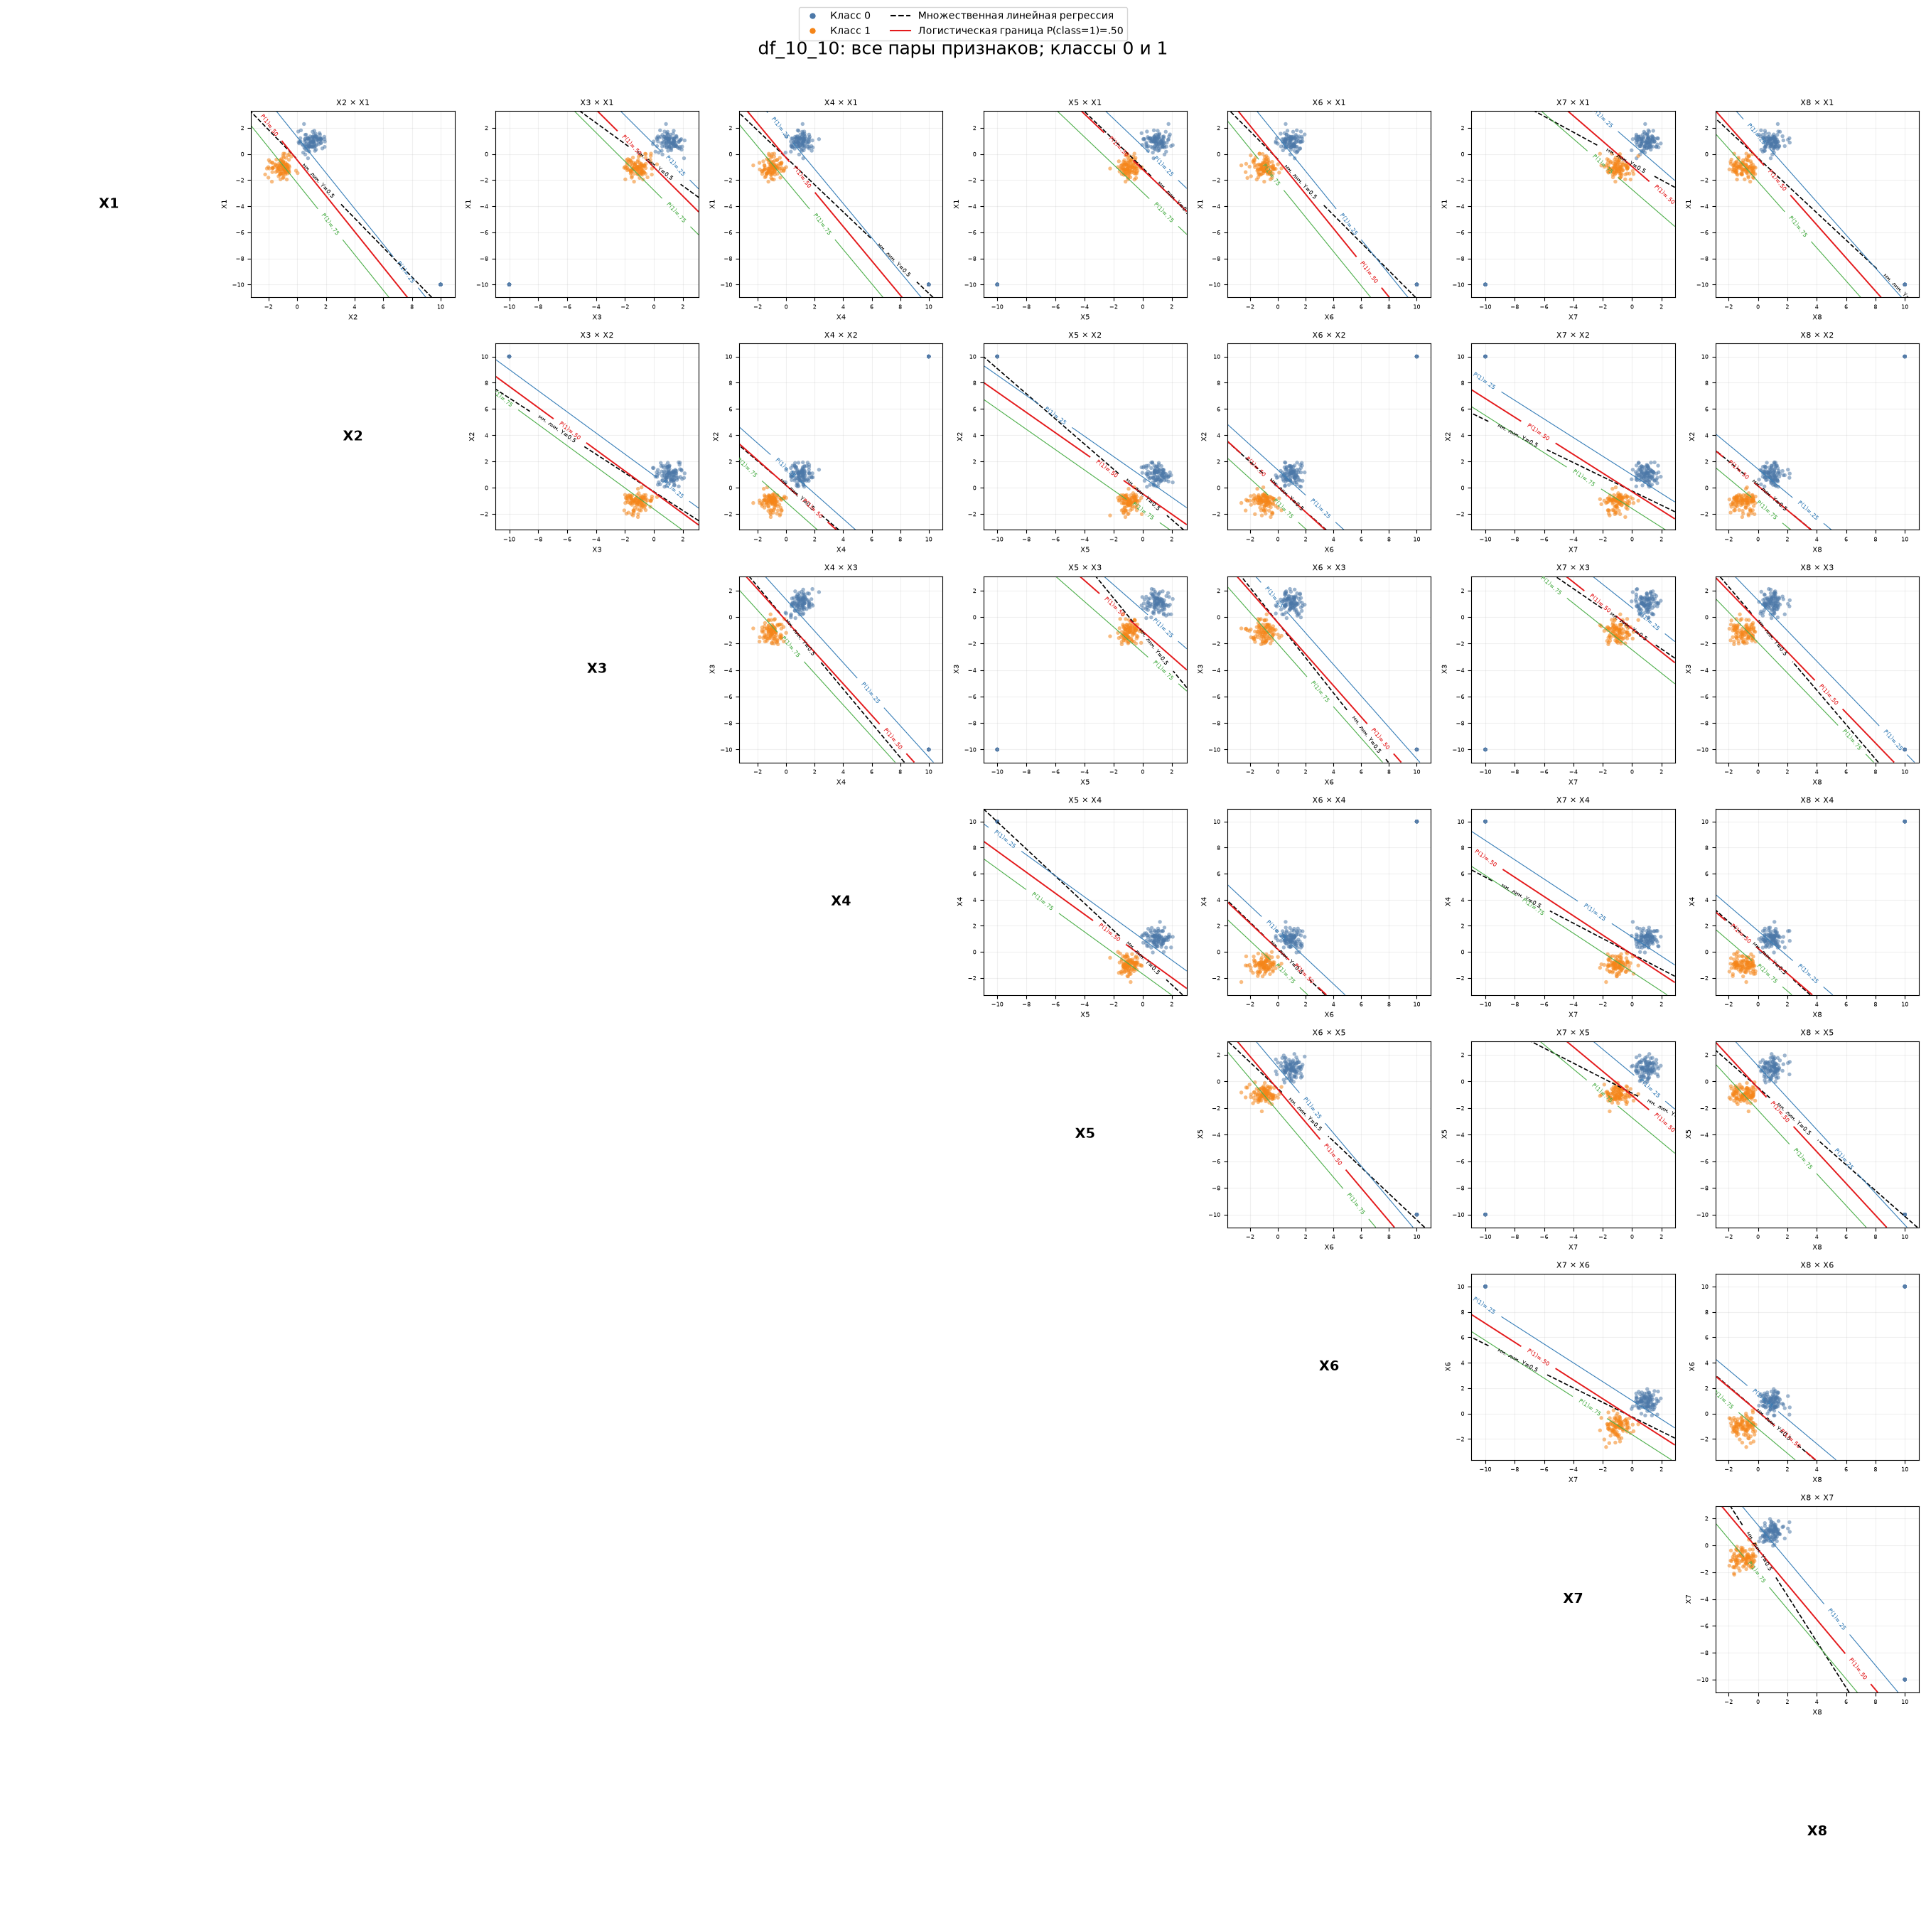

In [74]:
# ======================== НАСТРОЙКИ ПОЛЬЗОВАТЕЛЯ ========================
# Можно выбрать любую пару существующих классов.
SELECTED_CLASSES_46 = [0, 1]
# Выбор одного дополнительного датасета: (A, B) соответствует df_A_B.
DATASET_46 = (10, 10)

if len(SELECTED_CLASSES_46) != 2 or len(set(SELECTED_CLASSES_46)) != 2:
    raise ValueError("SELECTED_CLASSES_46 должен содержать ровно два разных класса")
if not set(SELECTED_CLASSES_46).issubset(set(df[CLASS_COL].unique())):
    raise ValueError(f"Доступные классы: {sorted(df[CLASS_COL].unique())}")
if DATASET_46 not in datasets_A_B:
    raise ValueError(f"Доступные датасеты df_A_B: {sorted(datasets_A_B)}")

negative_class_46, positive_class_46 = SELECTED_CLASSES_46
data_46 = datasets_A_B[DATASET_46]
selected_46 = data_46[data_46[CLASS_COL].isin(SELECTED_CLASSES_46)].dropna(
    subset=FEATURES + [CLASS_COL]
).copy()

# Внутреннее бинарное кодирование: первый выбранный класс = 0, второй = 1.
selected_46["Y_binary"] = (selected_46[CLASS_COL] == positive_class_46).astype(int)
X_46 = selected_46[FEATURES]
y_46 = selected_46["Y_binary"]

# Множественная линейная и логистическая регрессии используют все 8 признаков.
linear_model_46 = LinearRegression().fit(X_46, y_46)
logistic_model_46 = LogisticRegression(solver="lbfgs", random_state=42).fit(X_46, y_46)

def predict_projection_46(model, x_grid, y_grid, feature_x, feature_y, model_type):
    """Предсказания модели в двумерной проекции при медианных прочих признаках."""
    x_flat = np.asarray(x_grid).ravel()
    y_flat = np.asarray(y_grid).ravel()
    grid = pd.DataFrame(
        np.tile(X_46.median().to_numpy(), (x_flat.size, 1)),
        columns=FEATURES
    )
    grid[feature_x] = x_flat
    grid[feature_y] = y_flat
    if model_type == "linear":
        return model.predict(grid).reshape(x_grid.shape)
    return model.predict_proba(grid)[:, 1].reshape(x_grid.shape)

# Матрица: верхний треугольник содержит все уникальные пары признаков.
n_features_46 = len(FEATURES)
fig_46, axes_46 = plt.subplots(
    n_features_46, n_features_46,
    figsize=(n_features_46 * 3.4, n_features_46 * 3.4),
    squeeze=False
)

for row, feature_y in enumerate(FEATURES):
    for col, feature_x in enumerate(FEATURES):
        ax = axes_46[row, col]
        if row == col:
            ax.axis("off")
            ax.text(0.5, 0.5, feature_x, ha="center", va="center",
                    fontsize=14, fontweight="bold")
            continue
        if col < row:
            ax.axis("off")
            continue

        for class_id in SELECTED_CLASSES_46:
            block = selected_46[selected_46[CLASS_COL] == class_id]
            ax.scatter(
                block[feature_x], block[feature_y], s=15, alpha=0.55,
                color=CLASS_PALETTE[class_id], label=f"Класс {class_id}",
                edgecolors="none"
            )

        x_min, x_max = selected_46[feature_x].min(), selected_46[feature_x].max()
        y_min, y_max = selected_46[feature_y].min(), selected_46[feature_y].max()
        x_values = np.linspace(x_min - 0.08 * (x_max - x_min + 1e-12),
                               x_max + 0.08 * (x_max - x_min + 1e-12), 80)
        y_values = np.linspace(y_min - 0.08 * (y_max - y_min + 1e-12),
                               y_max + 0.08 * (y_max - y_min + 1e-12), 80)
        mesh_x, mesh_y = np.meshgrid(x_values, y_values)
        linear_surface = predict_projection_46(
            linear_model_46, mesh_x, mesh_y, feature_x, feature_y, "linear"
        )
        logistic_surface = predict_projection_46(
            logistic_model_46, mesh_x, mesh_y, feature_x, feature_y, "logistic"
        )

        # Контур множественной линейной регрессии: граница Y=0.5.
        if linear_surface.min() <= 0.5 <= linear_surface.max():
            linear_contour = ax.contour(
                mesh_x, mesh_y, linear_surface, levels=[0.5],
                colors="black", linestyles="--", linewidths=1.2
            )
            ax.clabel(linear_contour, fmt={0.5: "мн. лин. Y=0.5"}, fontsize=6)

        # Логистические уровни вероятности принадлежности к выбранному
        # положительному классу (второму в SELECTED_CLASSES_46).
        logistic_contour = ax.contour(
            mesh_x, mesh_y, logistic_surface, levels=[0.25, 0.50, 0.75],
            colors=["#377EB8", "#E41A1C", "#4DAF4A"], linewidths=[0.8, 1.4, 0.8]
        )
        ax.clabel(
            logistic_contour,
            fmt={0.25: f"P({positive_class_46})=.25",
                 0.50: f"P({positive_class_46})=.50",
                 0.75: f"P({positive_class_46})=.75"},
            fontsize=6
        )
        ax.set_title(f"{feature_x} × {feature_y}", fontsize=8)
        ax.set_xlabel(feature_x, fontsize=7)
        ax.set_ylabel(feature_y, fontsize=7)
        ax.tick_params(labelsize=6)
        ax.grid(alpha=0.18)

from matplotlib.lines import Line2D
legend_46 = [
    Line2D([0], [0], marker="o", color="w", label=f"Класс {negative_class_46}",
           markerfacecolor=CLASS_PALETTE[negative_class_46], markersize=7),
    Line2D([0], [0], marker="o", color="w", label=f"Класс {positive_class_46}",
           markerfacecolor=CLASS_PALETTE[positive_class_46], markersize=7),
    Line2D([0], [0], color="black", linestyle="--",
           label="Множественная линейная регрессия"),
    Line2D([0], [0], color="#E41A1C",
           label=f"Логистическая граница P(class={positive_class_46})=.50"),
]
fig_46.legend(handles=legend_46, loc="upper center", ncol=2,
              bbox_to_anchor=(0.5, 1.0), fontsize=10)
fig_46.suptitle(
    f"{f'df_{DATASET_46[0]}_{DATASET_46[1]}'}: все пары признаков; "
    f"классы {negative_class_46} и {positive_class_46}",
    fontsize=18
)
fig_46.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()